# Predicting UEFA Champions League Outcomes with EA Sports FC Data

**Columbia University · IEOR E4523 Data Analytics & Machine Learning · Group 17**  
Jiaxuan Liu

**Scope:** The primary dataset is `data/match_dataset/matches_full.csv`. Run from the repository root or set `UCL_DATA_DIR` to the directory containing the Builder CSV files. All charts and tables are exported to `analysis/eda_output/`. **Match labels are 90-minute outcomes**.

**Note:** Numeric input columns do not imply all are safe predictor features. We explicitly exclude IDs, post-match status/score flags, labels, and non-predictive metadata. Imputers/column filters are fitted on **2014–15 through 2023–24 only**, applied unchanged to 2024–25 validation, 2025–26 test, and 2026–27 fixtures.

## Data preparation

In [1]:
from pathlib import Path
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
import joblib

import warnings
warnings.filterwarnings("ignore")

DATA_DIR = Path(os.environ.get('UCL_DATA_DIR', 'data/match_dataset'))

if not (DATA_DIR / 'matches_full.csv').exists() and Path('../data/match_dataset/matches_full.csv').exists():
    DATA_DIR = Path('../data/match_dataset')

assert (DATA_DIR / 'matches_full.csv').exists(), f'Not found: {DATA_DIR.resolve()}'
OUT_DIR = Path(os.environ.get('UCL_EDA_OUT', 'analysis/eda_output'))
OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / 'figures').mkdir(exist_ok=True)
(OUT_DIR / 'tables').mkdir(exist_ok=True)
(OUT_DIR / 'prepared').mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 220, 'axes.spines.top': False, 'axes.spines.right': False})

compact = pd.read_csv(DATA_DIR / 'matches_compact.csv', low_memory=False)

full = pd.read_csv(DATA_DIR / 'matches_full.csv', low_memory=False)

canonical = pd.read_csv(DATA_DIR / 'matches_canonical.csv', low_memory=False)

fixtures_path = DATA_DIR / 'fixtures_2026_27_full.csv'
fixtures = pd.read_csv(fixtures_path, low_memory=False) if fixtures_path.exists() else None

print('Compact:', compact.shape, '| Full:', full.shape, '| Canonical:', canonical.shape)
print('Full player columns (examples):', [c for c in full if c.startswith('home_gk1_')][:8])

assert len(full) == len(compact) and full.match_id.equals(compact.match_id)
assert full.match_id.is_unique and compact.match_id.is_unique

Compact: (1433, 115) | Full: (1433, 819) | Canonical: (1766, 35)
Full player columns (examples): ['home_gk1_overall', 'home_gk1_potential', 'home_gk1_age', 'home_gk1_height_cm', 'home_gk1_weight_kg', 'home_gk1_weak_foot', 'home_gk1_skill_moves', 'home_gk1_movement_acceleration']


### 1.1 Column-level missingness

In [2]:
# exclude labels and categorical columns
labels = ['label_90min_wdl', 'label_90min_goal_diff', 'label_90min_home_goals', 'label_90min_away_goals', 'label_90min_home_win', 'label_90min_over25']
exclude = set(labels + [
    'match_id', 'season', 'match_date', 'fifa_version', 'home_team', 'away_team',
    'home_club_id', 'away_club_id', 'stage', 'status', 'score_source',
    'extra_time', 'has_penalties', 'both_clubs_mapped', 'both_squads_ready',
    'prediction_ready'
])

def predictor_cols(df):
    cols = [c for c in df.columns if c not in exclude]
    unexpected = [c for c in cols if not (pd.api.types.is_numeric_dtype(df[c]) or pd.api.types.is_bool_dtype(df[c]))]
    if unexpected: raise TypeError(f'Unencoded predictor columns: {unexpected}')
    return cols

compact_features, full_features = predictor_cols(compact), predictor_cols(full)
print('Predictor columns:', len(compact_features), '(Compact),', len(full_features), '(Full)')

for name, df, cols in [('Compact', compact, compact_features), ('Full', full, full_features)]:
    counts = df[cols].isnull().sum().sort_values(ascending=False)

    summary = pd.DataFrame({'missing_n':counts, 'missing_pct':(counts / len(df) * 100).round(2)})
    summary.query('missing_n > 0').to_csv(OUT_DIR / 'tables' / f'{name.lower()}_missing.csv')

    print(f'\n{name} nonzero missing columns ({(counts > 0).sum()}):')
    display(summary[summary.missing_n > 0].head(35))
    print('Missing cells:', int(counts.sum()), '| Completely empty columns:', int((counts == len(df)).sum()))
    
print('Historical labels missing:', full[labels].isnull().sum().to_dict())

Predictor columns: 93 (Compact), 797 (Full)

Compact nonzero missing columns (2):


,missing_n,missing_pct
away_bench_att_best_overall,224,15.63
home_bench_att_best_overall,222,15.49


Missing cells: 446 | Completely empty columns: 0

Full nonzero missing columns (24):


,missing_n,missing_pct
away_bench_att_best_overall,224,15.63
home_bench_att_best_overall,222,15.49
home_def1_mentality_composure,188,13.12
home_def3_mentality_composure,188,13.12
home_gk1_mentality_composure,188,13.12
home_def2_mentality_composure,188,13.12
home_mid2_mentality_composure,188,13.12
home_att2_mentality_composure,188,13.12
home_att1_mentality_composure,188,13.12
home_def4_mentality_composure,188,13.12


Missing cells: 4582 | Completely empty columns: 0
Historical labels missing: {'label_90min_wdl': 0, 'label_90min_goal_diff': 0, 'label_90min_home_goals': 0, 'label_90min_away_goals': 0, 'label_90min_home_win': 0, 'label_90min_over25': 0}


### 1.2  Missingness mechanism, time dependence and data checks
Check whether absent bench-forward quality exactly corresponds to **no remaining ATT player**. Check whether `mentality_composure` absence concentrates in earlier FIFA versions. Such missingness should not be treated as random. Also inspect duplicate keys, bad goal labels and training/validation/test composition.

In [3]:
for side in ['home', 'away']:
    rating=f'{side}_bench_att_best_overall'
    count=f'{side}_bench_att_count'
    print(side, '| rating missing:', int(full[rating].isna().sum()),
          '| missing & ATT count == 0:', int((full[rating].isna() & full[count].eq(0)).sum()),
          '| missing & count > 0:', int((full[rating].isna() & full[count].gt(0)).sum()))
    
composure = [c for c in full_features if c.endswith('_mentality_composure')]
print('Composure columns:',len(composure))

missing_by_season = full.groupby('season')[composure].apply(lambda x: x.isnull().mean().mean()).mul(100).round(1)
display(missing_by_season.rename('composure_missing_pct').to_frame())

print('Duplicate match IDs:', full.match_id.duplicated().sum())
print('Invalid 90-min scores:', int((full['label_90min_home_goals'].lt(0) | full['label_90min_away_goals'].lt(0)).sum()))
print('WD L label / score inconsistency:', int((np.select([full.label_90min_goal_diff > 0, full.label_90min_goal_diff < 0], ['H','A'],default='D') != full.label_90min_wdl).sum()))

display(full.groupby('season',sort=True).size().rename('trainable_matches').to_frame().T)
assert full[labels].notna().all().all()

home | rating missing: 222 | missing & ATT count == 0: 222 | missing & count > 0: 0
away | rating missing: 224 | missing & ATT count == 0: 224 | missing & count > 0: 0
Composure columns: 22


,composure_missing_pct
season,
2014-15,100.0
2015-16,100.0
2016-17,0.0
2017-18,0.0
2018-19,0.0
2019-20,0.0
2020-21,0.0
2021-22,0.0
2022-23,0.0


Duplicate match IDs: 0
Invalid 90-min scores: 0
WD L label / score inconsistency: 0


season,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26
trainable_matches,101,87,107,107,119,107,107,113,119,119,173,174


Missing values are limited and follow identifiable patterns. 

Missing bench attacker ratings occur exclusively when no eligible backup attackers are available, so they can be replaced with zero. Player composure ratings are entirely unavailable in the first two seasons but complete thereafter; therefore, we should exclude them from the core feature set and retain them for sensitivity analysis.

Data validation identified no duplicate match IDs, invalid scores, or inconsistencies between match outcomes and labels. Overall, the dataset is sufficiently clean for subsequent modeling, although historical team coverage remains uneven across seasons.

### 1.3 Time-aware Split

In [4]:
train_seasons = [f'{y}-{str(y+1)[-2:]}' for y in range(2014, 2024)]
valid_seasons = ['2024-25']
test_seasons = ['2025-26']
split_idx = {
    'train': full.season.isin(train_seasons),
    'valid': full.season.isin(valid_seasons),
    'test': full.season.isin(test_seasons)
}

print({k:int(v.sum()) for k,v in split_idx.items()})

club_cols = [c for c in compact_features if c.startswith(('home_club_','away_club_')) or c in ('neutral_venue','stage_league','stage_knockout')]
feature_sets = {
    'club_only':club_cols,
    'compact':compact_features,
    'full_core':[c for c in full_features if c not in composure],
    'full_all':full_features
}
print({name:len(cols) for name,cols in feature_sets.items()})

{'train': 1086, 'valid': 173, 'test': 174}
{'club_only': 15, 'compact': 93, 'full_core': 775, 'full_all': 797}


### 1.4 Prepare missing values and feature selection
- **Missing values:** If a team has no backup attackers, we set `bench_att_best_overall` to 0. Other missing values are filled using the median calculated from the training data.
- **Feature selection:** We remove constant columns and entirely missing columns. Missing indicators are added when necessary.
- **Model preparation:** All features are numeric. We prepare both original-scale and standardized datasets for different models. Match results, team names, IDs, and other information unavailable before a match are excluded.

In [5]:
from sklearn.base import BaseEstimator, TransformerMixin

class UCLPreprocessor(BaseEstimator, TransformerMixin):
    def __init__(self, columns): 
        self.columns = list(columns)

    def _base(self, df):
        x = df.reindex(columns=self.columns).copy()
        for c in x:
            if pd.api.types.is_bool_dtype(x[c]): 
                x[c] = x[c].astype('float64')
            else: 
                x[c] = pd.to_numeric(x[c], errors='coerce')
        x = x.replace([np.inf,-np.inf],np.nan)

        for side in ['home','away']:
            c = f'{side}_bench_att_best_overall'
            n = f'{side}_bench_att_count'
            if c in x and n in x:
                x.loc[x[c].isna() & x[n].eq(0), c] = 0.0
        return x
    
    def fit(self, df):
        x = self._base(df)
        self.all_null_cols_ = x.columns[x.isna().all()].tolist()
        x = x.drop(columns=self.all_null_cols_)

        # A column with only one distinct non-null value carries no variation in train.
        self.constant_cols_ = [c for c in x if x[c].dropna().nunique() <= 1]
        self.kept_cols_ = [c for c in x if c not in self.constant_cols_]

        self.flag_cols_ = [c for c in self.kept_cols_ if x[c].isna().any()]
        self.medians_ = x[self.kept_cols_].median().astype(float)
        self.out_cols_ = self.kept_cols_ + [c + '__missing' for c in self.flag_cols_]

        return self
    
    def transform(self, df):
        x = self._base(df)[self.kept_cols_]
        flags = {c + '__missing': x[c].isna().astype('int8') for c in self.flag_cols_}
        x = x.fillna(self.medians_)
        for key, val in flags.items():
            x[key] = val
        x = x.astype('float64')
        if not np.isfinite(x.to_numpy()).all(): 
            raise ValueError('NaN/Inf after preprocessing')
        
        return x.reindex(columns=self.out_cols_)

processed = {}
preprocessors={}
scalers={}
for name, cols in feature_sets.items():
    prep = UCLPreprocessor(cols).fit(full.loc[split_idx['train']])
    frames={k:prep.transform(full.loc[mask]).reset_index(drop=True) for k,mask in split_idx.items()}
    scaler=StandardScaler().fit(frames['train'])

    processed[name]=frames
    preprocessors[name]=prep
    scalers[name]=scaler
    
    print(f'{name:10} {len(cols)} initial -> {len(prep.out_cols_)} numeric columns | train-constant: {len(prep.constant_cols_)} | all-null: {len(prep.all_null_cols_)} | flags: {len(prep.flag_cols_)}')
    print('  examples dropped:',prep.constant_cols_[:5])

club_only  15 initial -> 15 numeric columns | train-constant: 0 | all-null: 0 | flags: 0
  examples dropped: []
compact    93 initial -> 93 numeric columns | train-constant: 0 | all-null: 0 | flags: 0
  examples dropped: []
full_core  775 initial -> 753 numeric columns | train-constant: 22 | all-null: 0 | flags: 0
  examples dropped: ['home_gk1_skill_moves', 'home_gk1_role_mismatch', 'home_def1_role_mismatch', 'home_def2_role_mismatch', 'home_def3_role_mismatch']
full_all   797 initial -> 797 numeric columns | train-constant: 22 | all-null: 0 | flags: 22
  examples dropped: ['home_gk1_skill_moves', 'home_gk1_role_mismatch', 'home_def1_role_mismatch', 'home_def2_role_mismatch', 'home_def3_role_mismatch']


Club Only and Compact retained all their original features, while Full Core removed 22 constant columns.

Full All replaced 22 constant columns with 22 missing indicators, keeping 797 features in total.

### 1.5 Export cleaned data

In [6]:
for name, frames in processed.items():
    folder = OUT_DIR / 'prepared' / name
    folder.mkdir(parents=True, exist_ok=True)

    for part,x in frames.items():
        idx = full.index[split_idx[part]]
        info = full.loc[idx, ['match_id','season','match_date','home_team','away_team'] + labels].reset_index(drop=True)
        x.to_csv(folder/f'X_{part}_tree.csv',index=False)

        pd.DataFrame(scalers[name].transform(x),columns=x.columns).to_csv(folder/f'X_{part}_scaled.csv',index=False)
        info.to_csv(folder/f'y_meta_{part}.csv',index=False)
     
    joblib.dump({'preprocessor':preprocessors[name],'scaler':scalers[name], 'feature_names':preprocessors[name].out_cols_}, folder/'transformers.joblib')
    
    if fixtures is not None:
        ready = fixtures.loc[fixtures['prediction_ready'].eq(True)]
        xf = preprocessors[name].transform(ready)
        xf.to_csv(folder/'X_2026_27_ready_tree.csv',index=False)

        pd.DataFrame(scalers[name].transform(xf),columns=xf.columns).to_csv(folder/'X_2026_27_ready_scaled.csv',index=False)
        ready[['match_id','season','match_date','home_team','away_team','status']].to_csv(folder/'fixtures_ready_meta.csv',index=False)
        print(f'{name}: fixtures ready {len(xf)}/{len(fixtures)}')

with open(OUT_DIR/'prepared'/'preprocessing_summary.json','w',encoding='utf-8') as f:
    json.dump({name:{'input':len(cols),'output':len(preprocessors[name].out_cols_), 'train_constant':preprocessors[name].constant_cols_, 'train_all_null':preprocessors[name].all_null_cols_, 'missing_indicators':preprocessors[name].flag_cols_} for name,cols in feature_sets.items()}, f,indent=2)

print('Saved cleaned datasets and fitted transformers to', (OUT_DIR/'prepared').resolve())

club_only: fixtures ready 128/144
compact: fixtures ready 128/144
full_core: fixtures ready 128/144
full_all: fixtures ready 128/144
Saved cleaned datasets and fitted transformers to E:\vscode-L\PYTHON_CU\DA_ML_4523\project\fifa15_fc27\analysis\eda_output\prepared


## Part II Exploratory data analysis

In [7]:
# construct analysis columns
eda = full.copy()
eda['rating_gap'] = eda['home_club_overall'] - eda['away_club_overall']
eda['xi_gap'] = eda['home_xi_overall_mean'] - eda['away_xi_overall_mean']
eda['bench_gap'] = eda['home_bench_overall_mean'] - eda['away_bench_overall_mean']
eda['goal_diff'] = eda['label_90min_goal_diff']
eda['total_goals'] = eda['label_90min_home_goals'] + eda['label_90min_away_goals']
eda['home_win'] = (eda.label_90min_wdl=='H').astype(int)
eda['away_win'] = (eda.label_90min_wdl=='A').astype(int)

def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT_DIR/'figures'/f'{name}.png',bbox_inches='tight')
    plt.show()

def wilson_interval(successes, n, z=1.96):
    if n == 0:
        return (np.nan,np.nan)
    p = successes / n
    den = 1 + z*z /n
    center = (p + z*z / (2*n)) / den
    half = z * np.sqrt(p*(1 - p) / n + z*z / (4*n*n)) / den
    return center - half, center + half

### Finding 1: Does nominal home advantage persist when teams have comparable ratings?

Close-rated matches: 448 / 1433


,All matches,Close ratings (|gap| ≤ 2)
label_90min_wdl,,
H,47.2,45.1
D,20.1,23.2
A,32.7,31.7


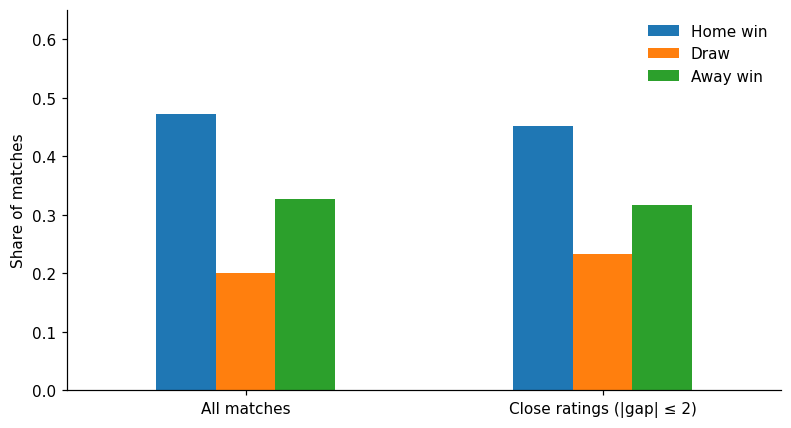

In [8]:
near = eda.loc[eda.rating_gap.abs() <= 2]
summary = pd.DataFrame({'All matches':eda.label_90min_wdl.value_counts(normalize=True),
                      'Close ratings (|gap| ≤ 2)':near.label_90min_wdl.value_counts(normalize=True)}).reindex(['H','D','A'])
print('Close-rated matches:',len(near),'/',len(eda))
display((summary*100).round(1))

fig,ax=plt.subplots(figsize=(7.3,4.0))
summary.T.plot(kind='bar',ax=ax,rot=0)
ax.set_ylabel('Share of matches')
ax.set_ylim(0,.65)
ax.legend(['Home win','Draw','Away win'],frameon=False)
savefig('01_home_advantage_close_ratings')

The nominal home-win share remains higher than the away-win share even among teams with similar EA FC overall ratings.

This motivates retaining a home/neutral context indicator alongside team-strength inputs.

### Finding 2: How does the rating gap relate to actual outcomes?

,band,n,home_win,away_win,home_low,home_high,mean_goal_diff
0,≤ -10,85,0.176,0.682,0.110,0.271,-1.494
1,"(-10, -5]",231,0.208,0.571,0.160,0.265,-0.905
2,"(-5, -2]",252,0.357,0.417,0.301,0.418,-0.171
3,"(-2, 2]",375,0.469,0.304,0.419,0.520,0.400
4,"(2, 5]",240,0.638,0.158,0.575,0.696,1.125
5,"(5, 10]",190,0.768,0.095,0.703,0.823,1.811
6,> 10,60,0.817,0.050,0.701,0.894,2.533


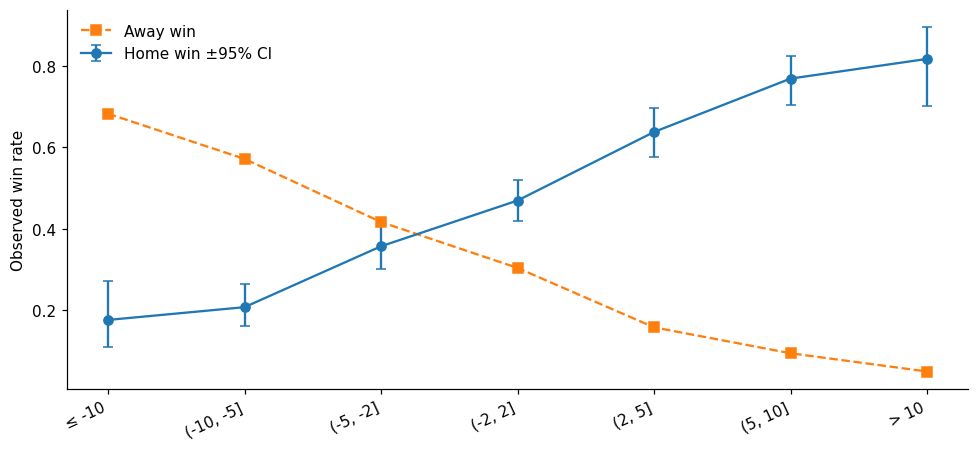

Pearson corr(rating gap, 90-minute goal difference): 0.494


In [9]:
bounds = [-np.inf, -10, -5, -2, 2, 5, 10, np.inf]
labels_gap = ['≤ -10','(-10, -5]','(-5, -2]','(-2, 2]','(2, 5]','(5, 10]','> 10']
eda['gap_band'] = pd.cut(eda.rating_gap, bins=bounds, labels=labels_gap, include_lowest=True)
rows=[]

for band, g in eda.groupby('gap_band',observed=True,sort=True):
    n = len(g)
    h = g.home_win.sum()
    a = g.away_win.sum()
    low, high = wilson_interval(h, n)
    rows.append({'band':str(band), 'n':n, 'home_win':h/n, 'away_win':a/n, 'home_low':low, 'home_high':high, 'mean_goal_diff':g.goal_diff.mean()})

gap_summary=pd.DataFrame(rows)
display(gap_summary.round(3))
gap_summary.to_csv(OUT_DIR/'tables'/'rating_gap_outcomes.csv', index=False)

fig, ax = plt.subplots(figsize=(9,4.2))
x = np.arange(len(gap_summary))
ax.errorbar(x, gap_summary.home_win, yerr=[gap_summary.home_win-gap_summary.home_low,gap_summary.home_high-gap_summary.home_win], fmt='o-', capsize=3, label='Home win ±95% CI')
ax.plot(x, gap_summary.away_win, 's--', label='Away win')
ax.set_xticks(x, gap_summary.band, rotation=25, ha='right')
ax.set_ylabel('Observed win rate')
ax.legend(frameon=False)
savefig('02_rating_gap_win_rates')
print('Pearson corr(rating gap, 90-minute goal difference):', round(eda[['rating_gap','goal_diff']].corr().iloc[0,1], 3))

The win-rate gradient across strength-gap bands suggests that relative team quality is strongly associated with match outcomes.

Ratings are predictive proxies rather than calibrated probabilities; departures from perfect symmetry motivate testing nonlinear learners and venue controls.

### Finding 3: Is the strength relationship stable across seasons?
The league format changed in 2024–25, and the ratings come from different annual game versions. Show per-season correlations and samples; avoid claiming one universal relationship without checking temporal stability.

,n,corr_gap_goaldiff,avg_goals
season,,,
2014-15,101.0,0.524,2.812
2015-16,87.0,0.627,2.782
2016-17,107.0,0.527,3.056
2017-18,107.0,0.445,3.243
2018-19,119.0,0.435,2.882
2019-20,107.0,0.481,3.206
2020-21,107.0,0.546,2.879
2021-22,113.0,0.507,3.009
2022-23,119.0,0.481,2.891


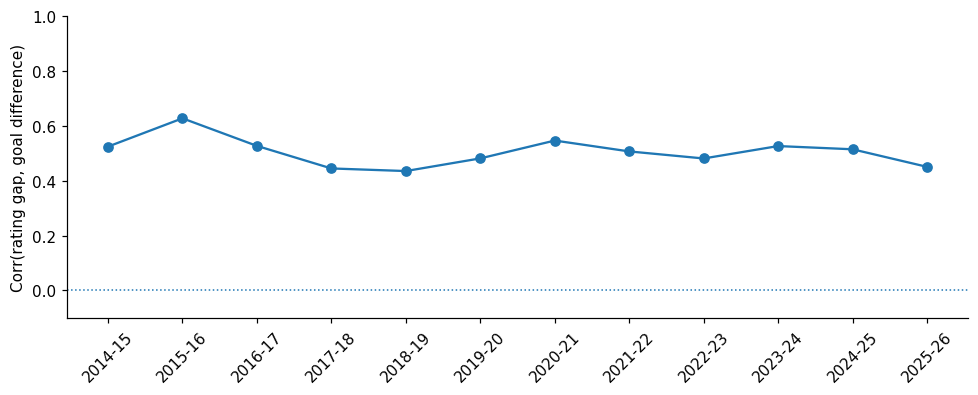

In [10]:
byseason = eda.groupby('season',sort=True).apply(lambda g:pd.Series({'n':len(g),'corr_gap_goaldiff':g[['rating_gap','goal_diff']].corr().iloc[0,1],'avg_goals':g.total_goals.mean()}),include_groups=False)
display(byseason.round(3))
byseason.to_csv(OUT_DIR/'tables'/'season_strength_stability.csv')

fig, ax = plt.subplots(figsize=(9,3.7))
ax.plot(byseason.index,byseason.corr_gap_goaldiff,marker='o')
ax.axhline(0,ls=':',lw=1)
ax.set_ylabel('Corr(rating gap, goal difference)')
ax.set_ylim(-.1,1)
ax.tick_params(axis='x',rotation=45)
savefig('03_season_strength_stability')

The association between preseason-style club ratings and outcomes is not identical across seasons. This supports a strict chronological validation/test split instead of randomly splitting matches that reuse the same season-level rosters.

### Finding 4: Does player/squad aggregation add information beyond the club rating?
Compare correlation with net goals and **in-sample OLS R² as a descriptive diagnostic**, using the exact same complete cases across specifications.

Correlations with 90-minute goal difference:


,Pearson r
rating_gap,0.494
xi_gap,0.488
bench_gap,0.401


,specification,in_sample_R2,n
0,rating_gap,0.24417,1433
1,rating_gap + xi_gap,0.24428,1433
2,rating_gap + xi_gap + bench_gap,0.24442,1433


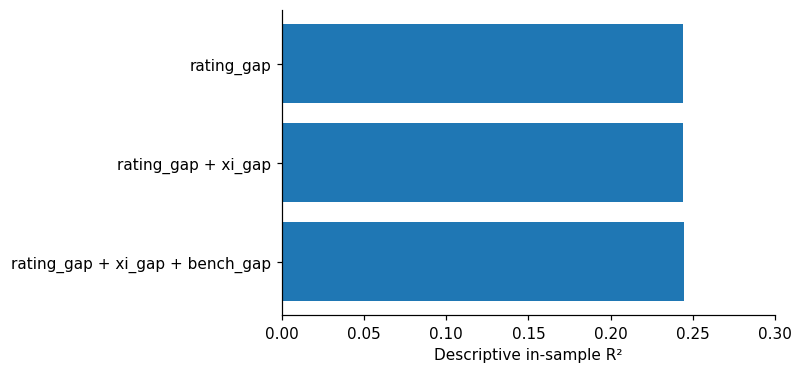

In [11]:
from sklearn.linear_model import LinearRegression

cols = ['rating_gap','xi_gap','bench_gap','goal_diff']
g = eda[cols].dropna()

specs = [['rating_gap'], ['rating_gap', 'xi_gap'], ['rating_gap', 'xi_gap', 'bench_gap']]
result=[]
for spec in specs:
    linear_model = LinearRegression().fit(g[spec], g.goal_diff)
    result.append({'specification':' + '.join(spec), 'in_sample_R2': linear_model.score(g[spec], g.goal_diff), 'n':len(g)})
result=pd.DataFrame(result)

print('Correlations with 90-minute goal difference:')
display(g.corr()['goal_diff'].drop('goal_diff').round(3).to_frame('Pearson r'))
display(result.round(5))
result.to_csv(OUT_DIR/'tables'/'aggregate_incremental_ols.csv',index=False)

fig, ax = plt.subplots(figsize=(7.4,3.5))
ax.barh(result.specification, result.in_sample_R2)
ax.invert_yaxis()
ax.set_xlabel('Descriptive in-sample R²')
ax.set_xlim(0, max(.30,result.in_sample_R2.max()*1.2))
savefig('04_aggregate_incremental_value')

Top-XI and bench rating aggregates are correlated with the actual goal difference but overlap heavily with club ratings.

Their limited incremental linear fit motivates a direct out-of-time comparison of Club Only, Compact, and Full (22-player) feature sets.

### Finding 5: Are goals compatible with a simple Poisson approximation?

Compare empirical total-goals frequencies against a Poisson distribution with the same mean, and report the variance-to-mean ratio.

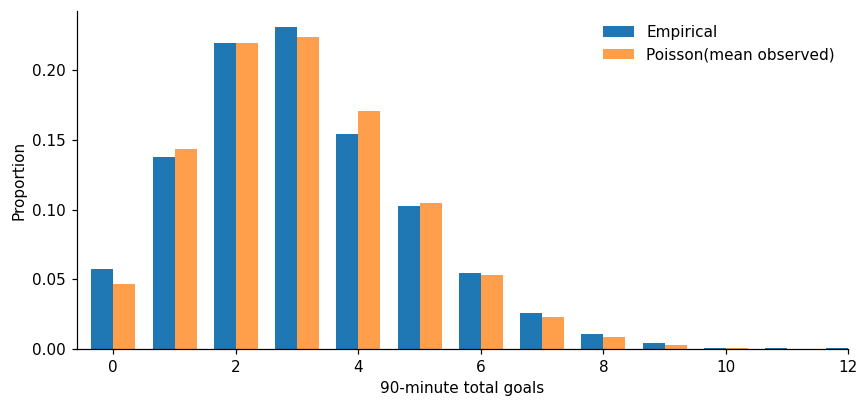

Mean: 3.057 | Variance: 3.317 | Variance/mean: 1.085


In [12]:
from scipy.stats import poisson

values = eda.total_goals.astype(int)
mu = values.mean()
var = values.var(ddof=1)

K = max(7, int(values.max()))
xs = np.arange(K+1)
obs = values.value_counts(normalize=True).reindex(xs,fill_value=0).values
expected = poisson.pmf(xs, mu)

fig, ax = plt.subplots(figsize=(8,3.8))
ax.bar(xs-0.18, obs, width=0.36, label='Empirical')
ax.bar(xs+.18, expected, width=.36, label='Poisson(mean observed)', alpha=.75)
ax.set_xlim(-.6,min(K+1,12))
ax.set_xlabel('90-minute total goals')
ax.set_ylabel('Proportion');ax.legend(frameon=False)
savefig('05_goal_distribution_poisson')

print(f'Mean: {mu:.3f} | Variance: {var:.3f} | Variance/mean: {var/mu:.3f}')

Total goals have a distribution broadly reminiscent of a Poisson count process, making home- and away-goal models a natural probabilistic baseline.

Any extra dispersion, team dependence, and score correlation will need to be evaluated using held-out log likelihood or calibration.

### Finding 6: Is the observed training sample representative of all historical UCL matches?

,all_matches,squad_ready,coverage_pct
season,,,
2014-15,125,101,80.8
2015-16,125,87,69.6
2016-17,125,107,85.6
2017-18,125,107,85.6
2018-19,125,119,95.2
2019-20,119,107,89.9
2020-21,125,107,85.6
2021-22,125,113,90.4
2022-23,125,119,95.2


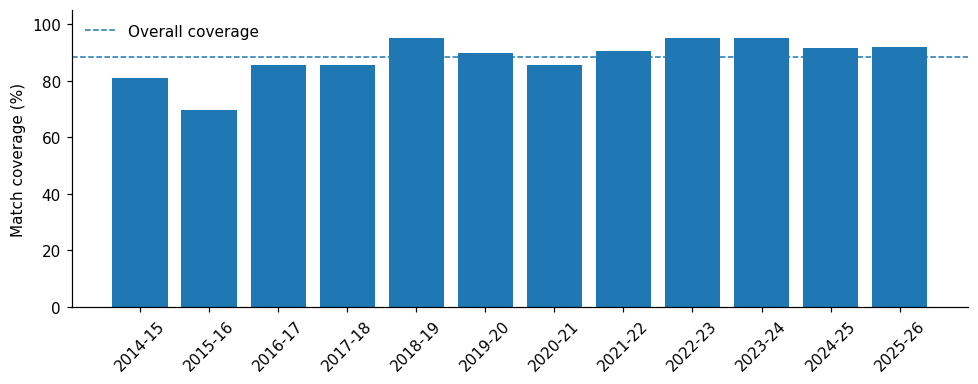

Overall coverage: 88.3 %


In [13]:
hist = canonical.loc[canonical.season.ne('2026-27')].copy()
raw_n = hist.groupby('season').size().rename('all_matches')
kept_n = eda.groupby('season').size().rename('squad_ready')

cov = pd.concat([raw_n, kept_n], axis=1).fillna(0)
cov['coverage_pct'] = 100 * cov.squad_ready / cov.all_matches

display(cov.round(1))
cov.to_csv(OUT_DIR/'tables'/'match_coverage_by_season.csv')

fig, ax = plt.subplots(figsize=(9,3.6))
ax.bar(cov.index, cov.coverage_pct)
ax.set_ylim(0,105)
ax.axhline(cov.squad_ready.sum()/cov.all_matches.sum()*100, ls='--', lw=1, label='Overall coverage')
ax.set_ylabel('Match coverage (%)')
ax.tick_params(axis='x',rotation=45)
ax.legend(frameon=False)

savefig('06_coverage_bias')
print('Overall coverage:', round(cov.squad_ready.sum()/cov.all_matches.sum()*100, 1), '%')

Missing EA club coverage is uneven across UCL seasons, so performance and descriptive findings for the matched sample may not generalize to underrepresented clubs. 

## Part III Modeling and validation

Train multiple machine learning models on six prediction tasks (90-minute H/D/A, goal difference, home goals, away goals, home win, over 2.5 goals) to compare different approaches. Simple club-level features performed competitively and often outperformed more detailed player-level features, suggesting that additional complexity does not always improve predictions.

In [15]:
from pathlib import Path
import warnings, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, PoissonRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import (accuracy_score, f1_score, log_loss, roc_auc_score,
    mean_absolute_error, mean_squared_error, r2_score, mean_poisson_deviance,
    confusion_matrix, ConfusionMatrixDisplay, brier_score_loss)
from sklearn.inspection import permutation_importance

In [17]:
from xgboost import XGBClassifier, XGBRegressor
from catboost import CatBoostClassifier, CatBoostRegressor

In [19]:
HAS_XGB = True
HAS_CAT = True

PREPARED = OUT_DIR / 'prepared' if 'OUT_DIR' in globals() else Path('analysis/eda_output/prepared')
if not PREPARED.exists() and Path('../analysis/eda_output/prepared').exists():
    PREPARED = Path('../analysis/eda_output/prepared')

RESULTS = Path('model/results')
if not Path('data').exists() and Path('../data').exists(): 
    RESULTS = Path('../model/results')
RESULTS.mkdir(parents=True, exist_ok=True)
(RESULTS/'models').mkdir(exist_ok=True)
(RESULTS/'figures').mkdir(exist_ok=True)
(RESULTS/'predictions').mkdir(exist_ok=True)

RANDOM_SEED = 42
QUICK_RUN = False
FEATURE_SETS = ['club_only', 'compact', 'full_core']
RUN_MLP = True

### 3.1 Load dataset

Use `scaled` data for Logistic/Linear Regression, KNN, SVM and MLP; use `tree` data for tree ensembles. The six target columns never enter `X`.

In [20]:
_cache = {}
def load_split(feature_set, split, scale='tree'):
    key = (feature_set, split, scale)
    if key not in _cache:
        folder = PREPARED / feature_set
        X = pd.read_csv(folder/f'X_{split}_{scale}.csv')
        meta = pd.read_csv(folder/f'y_meta_{split}.csv')
        _cache[key] = (X, meta)
    return _cache[key]

for fs in FEATURE_SETS:
    Xtr, ytr = load_split(fs,'train')
    Xva, yva = load_split(fs,'valid')
    Xte, yte = load_split(fs,'test')
    print(f'{fs:10}: {Xtr.shape[0]} train / {Xva.shape[0]} valid / {Xte.shape[0]} test, {Xtr.shape[1]} features')

TASKS = {
    'wdl': {'label':'label_90min_wdl','type':'multi','metric':'log_loss'},
    'goal_diff': {'label':'label_90min_goal_diff','type':'reg','metric':'mae'},
    'home_goals': {'label':'label_90min_home_goals','type':'count','metric':'mae'},
    'away_goals': {'label':'label_90min_away_goals','type':'count','metric':'mae'},
    'home_win': {'label':'label_90min_home_win','type':'binary','metric':'log_loss'},
    'over25': {'label':'label_90min_over25','type':'binary','metric':'log_loss'},
}

club_only : 1086 train / 173 valid / 174 test, 15 features
compact   : 1086 train / 173 valid / 174 test, 93 features
full_core : 1086 train / 173 valid / 174 test, 753 features


### 3.2 Model Runner

In [21]:
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import balanced_accuracy_score

# consistent class order
def encode_target(task, series):
    if task == 'wdl':
        return pd.Categorical(series, categories=['A','D','H']).codes
    return pd.to_numeric(series,errors='raise').to_numpy()

def make_models(task):
    kind=TASKS[task]['type']
    classify = kind in ('multi','binary')
    models = {}
    if classify:
        models['Dummy'] = (DummyClassifier(strategy='prior'), 'tree')
        models['Logistic'] = (LogisticRegression(max_iter=2500, random_state=RANDOM_SEED), 'scaled')
        models['DecisionTree'] = (DecisionTreeClassifier(max_depth=5, min_samples_leaf=12, random_state=RANDOM_SEED), 'tree')
        models['KNN'] = (KNeighborsClassifier(n_neighbors=25, weights='distance'), 'scaled')
        models['SVM'] = (SVC(C=1.0, probability=True, random_state=RANDOM_SEED), 'scaled')
        models['RandomForest'] = (RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=4, n_jobs=-1, random_state=RANDOM_SEED), 'tree')
        models['HistGB'] = (HistGradientBoostingClassifier(max_iter=150,max_leaf_nodes=15,l2_regularization=5,random_state=RANDOM_SEED),'tree')
        # XGB
        opts = dict(n_estimators=220,max_depth=3,learning_rate=0.04,subsample=.85,colsample_bytree=.85,reg_lambda=5,tree_method='hist',random_state=RANDOM_SEED,n_jobs=4)
        if kind == 'multi': 
            opts.update(objective='multi:softprob', num_class=3)
        else: 
            opts.update(objective='binary:logistic')
        models['XGBoost'] = (XGBClassifier(**opts), 'tree')
        # CatBoost
        opts = dict(iterations=260,depth=4,learning_rate=.04,l2_leaf_reg=5,verbose=False,random_seed=RANDOM_SEED,thread_count=4)
        models['CatBoost'] = (CatBoostClassifier(loss_function='MultiClass' if kind=='multi' else 'Logloss',**opts),'tree')
        # MLP
        models['MLP'] = (MLPClassifier(hidden_layer_sizes=(64,32), alpha=5, early_stopping=True, n_iter_no_change=15, max_iter=250, random_state=RANDOM_SEED), 'scaled')
    
    else: # Regression
        models['Dummy'] = (DummyRegressor(strategy='mean'),'tree')
        models['Linear'] = (LinearRegression(),'scaled')
        models['Ridge'] = (Ridge(alpha=50.0),'scaled')
        models['DecisionTree'] = (DecisionTreeRegressor(max_depth=5,min_samples_leaf=12,random_state=RANDOM_SEED),'tree')
        models['KNN'] = (KNeighborsRegressor(n_neighbors=25,weights='distance'),'scaled')
        models['SVR'] = (SVR(C=1.0,epsilon=.2),'scaled')
        models['RandomForest'] = (RandomForestRegressor(n_estimators=200,max_depth=10,min_samples_leaf=4,n_jobs=-1,random_state=RANDOM_SEED),'tree')
        models['HistGB'] = (HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=15,l2_regularization=5,random_state=RANDOM_SEED),'tree')
        if kind == 'count':
            models['Poisson']=(PoissonRegressor(alpha=1,max_iter=1000),'scaled')
        # XGB
        objective = 'count:poisson' if kind=='count' else 'reg:squarederror'
        models['XGBoost'] = (XGBRegressor(objective=objective,n_estimators=220,max_depth=3,learning_rate=.04,subsample=.85,colsample_bytree=.85,reg_lambda=5,tree_method='hist',n_jobs=4,random_state=RANDOM_SEED),'tree')
        # CatBoost
        models['CatBoost'] = (CatBoostRegressor(loss_function='Poisson' if kind=='count' else 'RMSE',iterations=260,depth=4,learning_rate=.04,l2_leaf_reg=5,verbose=False,random_seed=RANDOM_SEED,thread_count=4),'tree')
        # MLP
        models['MLP']=(MLPRegressor(hidden_layer_sizes=(64,32),alpha=5,early_stopping=True,n_iter_no_change=15,max_iter=250,random_state=RANDOM_SEED),'scaled')
    
    if QUICK_RUN:
        keep={'Dummy','Logistic','Linear','Ridge','Poisson','DecisionTree','RandomForest','XGBoost','CatBoost','MLP'}
        models={k:v for k,v in models.items() if k in keep}

    return models

def calculate_metrics(task,y_true, model, X):
    kind = TASKS[task]['type']
    y = np.asarray(y_true)
    if kind in ('multi','binary'):
        probs = model.predict_proba(X)
        classes = np.asarray(model.classes_, dtype=int)
        if kind == 'multi':
            fullprob = np.zeros((len(y),3))
            fullprob[:,classes] = probs
            fullprob = np.clip(fullprob, 1e-10, 1)
            fullprob /= fullprob.sum(axis=1, keepdims=True)
            pred = fullprob.argmax(axis=1)
            return {'log_loss':log_loss(y,fullprob,labels=[0,1,2]),'accuracy':accuracy_score(y,pred),
                    'macro_f1':f1_score(y,pred,average='macro',zero_division=0)}, fullprob, pred
        pos = np.flatnonzero(classes==1)
        p = probs[:,pos[0]] if len(pos) else np.zeros(len(y))
        p = np.clip(p,1e-10,1-1e-10)
        pred = (p>=.5).astype(int)
        metrics = {'log_loss':log_loss(y,np.c_[1-p,p],labels=[0,1]),
                  'accuracy':accuracy_score(y,pred),'f1':f1_score(y,pred,zero_division=0),
                  'brier':brier_score_loss(y,p)}
        metrics['roc_auc'] = roc_auc_score(y,p) if len(np.unique(y)) == 2 else np.nan
        return metrics, p, pred
    
    pred = np.asarray(model.predict(X), dtype=float)
    if kind == 'count': 
        pred = np.maximum(pred, 1e-8)
    m = {'mae':mean_absolute_error(y,pred),'rmse':np.sqrt(mean_squared_error(y,pred)), 'r2':r2_score(y,pred)}
    if kind=='count':
        m['poisson_deviance'] = mean_poisson_deviance(y,pred)

    return m, pred, pred

In [22]:
def run_task(task, feature_sets=None):
    if feature_sets is None: 
        feature_sets = FEATURE_SETS

    setting = TASKS[task]
    records, winners = [], []
    
    for fs in feature_sets:
        tr_meta = load_split(fs,'train')[1]
        va_meta = load_split(fs,'valid')[1]
        y_train = encode_target(task, tr_meta[setting['label']])
        y_valid = encode_target(task, va_meta[setting['label']])

        candidates = []
        for model_name, (est, scale) in make_models(task).items():
            X_train = load_split(fs,'train',scale)[0]
            X_valid = load_split(fs,'valid',scale)[0]
            t0 = time.time()
            try:
                fitted = clone(est).fit(X_train, y_train)
                val_metrics, probs, pred=calculate_metrics(task, y_valid, fitted, X_valid)
                item={'task':task, 'feature_set':fs, 'model':model_name, 'scale':scale, 'seconds':round(time.time()-t0,1), **val_metrics}
                records.append(item)
                candidates.append((item, fitted))
            except Exception as e:
                print(f'[Skipped] {task} / {fs} / {model_name}: {str(e)[:140]}')
        if not candidates: 
            continue

        trees = {'DecisionTree','RandomForest','HistGB','XGBoost','CatBoost'}
        tree_candidates = [(r,m) for r,m in candidates if r['model'] in trees]
        if tree_candidates:
            tree_row, tree_model = min(tree_candidates, key=lambda v: v[0][setting['metric']])
            joblib.dump({'model':tree_model,'task':task,'feature_set':fs,'scale':tree_row['scale'],
                         'columns':load_split(fs,'valid',tree_row['scale'])[0].columns.tolist()},
                         RESULTS/'models'/f'{task}_{fs}_best_tree.joblib')
            
        metric = setting['metric']
        best_row, best_model = min(candidates, key=lambda v: v[0][metric])
        X_test, test_meta = load_split(fs, 'test', best_row['scale'])
        y_test = encode_target(task, test_meta[setting['label']])
        test_scores, test_probs, test_pred = calculate_metrics(task, y_test, best_model, X_test)
        test_row={'task': task, 'feature_set': fs, 'model': best_row['model'],
                  'selection_metric': metric, 'valid_score': best_row[metric], **{f'test_{k}':v for k,v in test_scores.items()}}
        winners.append(test_row)
        filename=f'{task}_{fs}_{best_row["model"]}'
        joblib.dump({'model': best_model, 'task': task, 'feature_set': fs, 'scale': best_row['scale'],
                     'columns': X_test.columns.tolist(), 'class_names': ['A','D','H'] if task=='wdl' else None}, RESULTS/'models'/f'{filename}.joblib')
        
        out = test_meta[['match_id','season','home_team','away_team']].copy()
        out['actual'] = y_test
        if setting['type'] == 'multi':
            out[['p_away','p_draw','p_home']] = test_probs
            out['predicted'] = test_pred
        elif setting['type'] == 'binary':
            out['probability'] = test_probs
            out['predicted'] = test_pred
        else:
            out['predicted'] = test_pred

        out.to_csv(RESULTS/'predictions'/f'{filename}_test.csv',index=False)
        print(f'{task:12} {fs:10} | best {best_row["model"]:13} | valid {metric}={best_row[metric]:.4f} | test {metric}={test_scores[metric]:.4f}')

    table = pd.DataFrame(records)
    selected = pd.DataFrame(winners)
    table.to_csv(RESULTS/f'{task}_validation_all.csv',index=False)
    selected.to_csv(RESULTS/f'{task}_test_selected.csv',index=False)
    if not table.empty:
        display(table.sort_values(['feature_set',setting['metric']]).round(4))
    if not selected.empty:
        display(selected.round(4))
    return table, selected

### 3.3 Run the six prediction tasks

In [23]:
all_validation = {}
all_selected = {}

**90-minute W / D / L**

In [24]:
# Run wdl
all_validation['wdl'], all_selected['wdl'] = run_task('wdl')

wdl          club_only  | best Logistic      | valid log_loss=0.9304 | test log_loss=0.9702
wdl          compact    | best KNN           | valid log_loss=0.9309 | test log_loss=1.0754
wdl          full_core  | best CatBoost      | valid log_loss=0.9387 | test log_loss=0.9328


,task,feature_set,model,scale,seconds,log_loss,accuracy,macro_f1
1,wdl,club_only,Logistic,scaled,0.0,0.9304,0.5723,0.4312
9,wdl,club_only,MLP,scaled,0.1,0.9394,0.5780,0.4144
8,wdl,club_only,CatBoost,tree,0.3,0.9724,0.5434,0.3867
4,wdl,club_only,SVM,scaled,0.2,0.9752,0.5723,0.4077
0,wdl,club_only,Dummy,tree,0.0,1.0105,0.5087,0.2248
5,wdl,club_only,RandomForest,tree,0.3,1.0117,0.5202,0.4090
7,wdl,club_only,XGBoost,tree,0.1,1.0160,0.5376,0.4256
3,wdl,club_only,KNN,scaled,0.0,1.1071,0.5491,0.4143
6,wdl,club_only,HistGB,tree,3.5,1.2466,0.4971,0.4239
2,wdl,club_only,DecisionTree,tree,0.0,1.7579,0.5434,0.3947


,task,feature_set,model,selection_metric,valid_score,test_log_loss,test_accuracy,test_macro_f1
0,wdl,club_only,Logistic,log_loss,0.9304,0.9702,0.5632,0.4184
1,wdl,compact,KNN,log_loss,0.9309,1.0754,0.5920,0.4418
2,wdl,full_core,CatBoost,log_loss,0.9387,0.9328,0.5460,0.3874


**Goal difference (regression)**

In [25]:
# Run goal_diff
all_validation['goal_diff'], all_selected['goal_diff'] = run_task('goal_diff')

goal_diff    club_only  | best Ridge         | valid mae=1.5709 | test mae=1.5897
goal_diff    compact    | best KNN           | valid mae=1.5822 | test mae=1.5678
goal_diff    full_core  | best RandomForest  | valid mae=1.5764 | test mae=1.5999


,task,feature_set,model,scale,seconds,mae,rmse,r2
2,goal_diff,club_only,Ridge,scaled,0.0,1.5709,2.0030,0.2377
1,goal_diff,club_only,Linear,scaled,0.0,1.5739,2.0085,0.2335
10,goal_diff,club_only,MLP,scaled,0.1,1.5959,2.0393,0.2098
4,goal_diff,club_only,KNN,scaled,0.0,1.6015,2.0618,0.1923
5,goal_diff,club_only,SVR,scaled,0.0,1.6234,2.0916,0.1687
9,goal_diff,club_only,CatBoost,tree,0.1,1.6287,2.0771,0.1802
8,goal_diff,club_only,XGBoost,tree,0.1,1.6520,2.1072,0.1563
6,goal_diff,club_only,RandomForest,tree,0.2,1.6792,2.1479,0.1234
7,goal_diff,club_only,HistGB,tree,0.5,1.6927,2.2075,0.0741
3,goal_diff,club_only,DecisionTree,tree,0.0,1.7446,2.1910,0.0879


,task,feature_set,model,selection_metric,valid_score,test_mae,test_rmse,test_r2
0,goal_diff,club_only,Ridge,mae,1.5709,1.5897,1.9470,0.2024
1,goal_diff,compact,KNN,mae,1.5822,1.5678,1.9471,0.2023
2,goal_diff,full_core,RandomForest,mae,1.5764,1.5999,1.9564,0.1946


**Home goals**

In [26]:
# Run home_goals
all_validation['home_goals'], all_selected['home_goals'] = run_task('home_goals')

home_goals   club_only  | best Poisson       | valid mae=1.0993 | test mae=1.2075
home_goals   compact    | best Poisson       | valid mae=1.1009 | test mae=1.2219
home_goals   full_core  | best CatBoost      | valid mae=1.0930 | test mae=1.2267


,task,feature_set,model,scale,seconds,mae,rmse,r2,poisson_deviance
8,home_goals,club_only,Poisson,scaled,0.0,1.0993,1.4560,0.1849,1.2798
2,home_goals,club_only,Ridge,scaled,0.0,1.1002,1.4570,0.1838,1.2780
1,home_goals,club_only,Linear,scaled,0.0,1.1029,1.4624,0.1776,1.2865
11,home_goals,club_only,MLP,scaled,0.3,1.1194,1.4830,0.1544,1.3546
9,home_goals,club_only,XGBoost,tree,0.1,1.1236,1.4903,0.1460,1.3453
10,home_goals,club_only,CatBoost,tree,0.2,1.1387,1.5037,0.1306,1.3746
4,home_goals,club_only,KNN,scaled,0.0,1.1412,1.5077,0.1259,1.3830
5,home_goals,club_only,SVR,scaled,0.0,1.1519,1.5565,0.0684,1.5107
6,home_goals,club_only,RandomForest,tree,0.3,1.1662,1.5186,0.1132,1.4085
3,home_goals,club_only,DecisionTree,tree,0.0,1.1837,1.5018,0.1328,1.3817


,task,feature_set,model,selection_metric,valid_score,test_mae,test_rmse,test_r2,test_poisson_deviance
0,home_goals,club_only,Poisson,mae,1.0993,1.2075,1.5214,0.0546,1.3919
1,home_goals,compact,Poisson,mae,1.1009,1.2219,1.5485,0.0206,1.4681
2,home_goals,full_core,CatBoost,mae,1.0930,1.2267,1.5475,0.0219,1.4403


**Away goals**

In [27]:
# Run away_goals
all_validation['away_goals'], all_selected['away_goals'] = run_task('away_goals')

away_goals   club_only  | best SVR           | valid mae=1.0281 | test mae=0.9718
away_goals   compact    | best XGBoost       | valid mae=1.0407 | test mae=0.9893
away_goals   full_core  | best CatBoost      | valid mae=1.0314 | test mae=0.9595


,task,feature_set,model,scale,seconds,mae,rmse,r2,poisson_deviance
5,away_goals,club_only,SVR,scaled,0.0,1.0281,1.3235,0.0928,1.5732
8,away_goals,club_only,Poisson,scaled,0.0,1.0346,1.3188,0.0993,1.3780
10,away_goals,club_only,CatBoost,tree,0.2,1.0396,1.3165,0.1025,1.3675
9,away_goals,club_only,XGBoost,tree,0.1,1.0417,1.3176,0.1010,1.3681
4,away_goals,club_only,KNN,scaled,0.0,1.0424,1.3236,0.0928,1.3779
2,away_goals,club_only,Ridge,scaled,0.0,1.0489,1.3258,0.0898,1.3872
11,away_goals,club_only,MLP,scaled,0.1,1.0492,1.3389,0.0717,1.4043
1,away_goals,club_only,Linear,scaled,0.0,1.0561,1.3360,0.0757,1.4055
6,away_goals,club_only,RandomForest,tree,0.2,1.0811,1.3637,0.0369,1.4644
7,away_goals,club_only,HistGB,tree,0.4,1.0940,1.3844,0.0075,1.5114


,task,feature_set,model,selection_metric,valid_score,test_mae,test_rmse,test_r2,test_poisson_deviance
0,away_goals,club_only,SVR,mae,1.0281,0.9718,1.2752,0.1243,1.3026
1,away_goals,compact,XGBoost,mae,1.0407,0.9893,1.2952,0.0966,1.3098
2,away_goals,full_core,CatBoost,mae,1.0314,0.9595,1.2425,0.1687,1.2248


**Home-win probability (classification)**

In [28]:
# Run home_win
all_validation['home_win'], all_selected['home_win'] = run_task('home_win')

home_win     club_only  | best Logistic      | valid log_loss=0.6460 | test log_loss=0.6191
home_win     compact    | best KNN           | valid log_loss=0.6441 | test log_loss=0.6249
home_win     full_core  | best RandomForest  | valid log_loss=0.6517 | test log_loss=0.6104


,task,feature_set,model,scale,seconds,log_loss,accuracy,f1,brier,roc_auc
1,home_win,club_only,Logistic,scaled,0.0,0.6460,0.6590,0.6335,0.2262,0.6952
9,home_win,club_only,MLP,scaled,0.1,0.6657,0.6127,0.5037,0.2364,0.6663
4,home_win,club_only,SVM,scaled,0.2,0.6773,0.6243,0.5638,0.2407,0.6521
8,home_win,club_only,CatBoost,tree,0.3,0.6913,0.6069,0.5584,0.2429,0.6587
0,home_win,club_only,Dummy,tree,0.0,0.6971,0.4913,0.0000,0.2520,0.5000
7,home_win,club_only,XGBoost,tree,0.1,0.7091,0.6069,0.5641,0.2510,0.6353
5,home_win,club_only,RandomForest,tree,0.3,0.7118,0.5954,0.5513,0.2511,0.6311
6,home_win,club_only,HistGB,tree,1.4,0.7879,0.5838,0.5663,0.2701,0.6246
3,home_win,club_only,KNN,scaled,0.0,0.7911,0.6012,0.5714,0.2351,0.6711
2,home_win,club_only,DecisionTree,tree,0.0,1.3359,0.6069,0.6136,0.2631,0.6415


,task,feature_set,model,selection_metric,valid_score,test_log_loss,test_accuracy,test_f1,test_brier,test_roc_auc
0,home_win,club_only,Logistic,log_loss,0.6460,0.6191,0.7011,0.6750,0.2127,0.7340
1,home_win,compact,KNN,log_loss,0.6441,0.6249,0.6724,0.6323,0.2155,0.7258
2,home_win,full_core,RandomForest,log_loss,0.6517,0.6104,0.6897,0.6625,0.2105,0.7353


**Over 2.5 total goals (classification)**

In [29]:
# Run over25
all_validation['over25'], all_selected['over25'] = run_task('over25')

over25       club_only  | best CatBoost      | valid log_loss=0.6601 | test log_loss=0.6497
over25       compact    | best CatBoost      | valid log_loss=0.6541 | test log_loss=0.6507
over25       full_core  | best RandomForest  | valid log_loss=0.6617 | test log_loss=0.6645


,task,feature_set,model,scale,seconds,log_loss,accuracy,f1,brier,roc_auc
8,over25,club_only,CatBoost,tree,0.2,0.6601,0.5954,0.7154,0.2347,0.5603
7,over25,club_only,XGBoost,tree,0.1,0.6637,0.5723,0.6917,0.2368,0.5530
1,over25,club_only,Logistic,scaled,0.0,0.6670,0.6358,0.7529,0.2369,0.5366
5,over25,club_only,RandomForest,tree,0.3,0.6686,0.5607,0.6935,0.2393,0.5074
0,over25,club_only,Dummy,tree,0.0,0.6686,0.6243,0.7687,0.2378,0.5000
4,over25,club_only,SVM,scaled,0.2,0.6692,0.6127,0.7599,0.2381,0.5178
9,over25,club_only,MLP,scaled,0.1,0.6728,0.6012,0.7396,0.2399,0.5291
3,over25,club_only,KNN,scaled,0.0,0.6748,0.5491,0.6803,0.2410,0.5301
2,over25,club_only,DecisionTree,tree,0.0,0.7080,0.5145,0.6410,0.2585,0.4808
6,over25,club_only,HistGB,tree,0.4,0.7119,0.5318,0.6524,0.2580,0.5244


,task,feature_set,model,selection_metric,valid_score,test_log_loss,test_accuracy,test_f1,test_brier,test_roc_auc
0,over25,club_only,CatBoost,log_loss,0.6601,0.6497,0.6322,0.7557,0.2286,0.5707
1,over25,compact,CatBoost,log_loss,0.6541,0.6507,0.5862,0.7143,0.2298,0.5568
2,over25,full_core,RandomForest,log_loss,0.6617,0.6645,0.6207,0.7591,0.2359,0.5066


### 3.4 Compare models and inspect errors on validation and test set

In [30]:
summary = pd.concat([x for x in all_selected.values() if len(x)], ignore_index=True)
display(summary.round(4))
summary.to_csv(RESULTS/'all_tasks_test_summary.csv',index=False)

,task,feature_set,model,selection_metric,valid_score,test_log_loss,test_accuracy,test_macro_f1,test_mae,test_rmse,test_r2,test_poisson_deviance,test_f1,test_brier,test_roc_auc
0,wdl,club_only,Logistic,log_loss,0.9304,0.9702,0.5632,0.4184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,wdl,compact,KNN,log_loss,0.9309,1.0754,0.5920,0.4418,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,wdl,full_core,CatBoost,log_loss,0.9387,0.9328,0.5460,0.3874,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,goal_diff,club_only,Ridge,mae,1.5709,NaN,NaN,NaN,1.5897,1.9470,0.2024,NaN,NaN,NaN,NaN
4,goal_diff,compact,KNN,mae,1.5822,NaN,NaN,NaN,1.5678,1.9471,0.2023,NaN,NaN,NaN,NaN
5,goal_diff,full_core,RandomForest,mae,1.5764,NaN,NaN,NaN,1.5999,1.9564,0.1946,NaN,NaN,NaN,NaN
6,home_goals,club_only,Poisson,mae,1.0993,NaN,NaN,NaN,1.2075,1.5214,0.0546,1.3919,NaN,NaN,NaN
7,home_goals,compact,Poisson,mae,1.1009,NaN,NaN,NaN,1.2219,1.5485,0.0206,1.4681,NaN,NaN,NaN
8,home_goals,full_core,CatBoost,mae,1.0930,NaN,NaN,NaN,1.2267,1.5475,0.0219,1.4403,NaN,NaN,NaN
9,away_goals,club_only,SVR,mae,1.0281,NaN,NaN,NaN,0.9718,1.2752,0.1243,1.3026,NaN,NaN,NaN


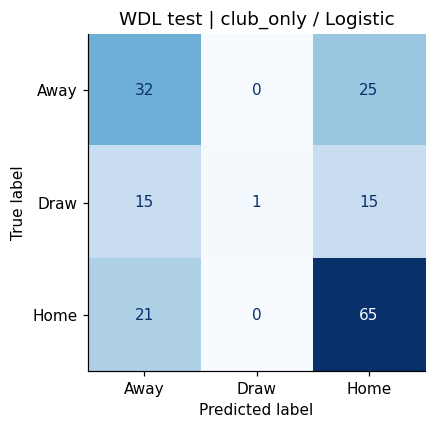

In [31]:
ranked = all_validation['wdl'].sort_values('log_loss')
choice = ranked.iloc[0]
path = RESULTS/'predictions'/f'wdl_{choice.feature_set}_{choice.model}_test.csv'
pred = pd.read_csv(path)

fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(pred.actual,pred.predicted,
    labels=[0,1,2], display_labels=['Away','Draw','Home'], ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'WDL test | {choice.feature_set} / {choice.model}')
fig.tight_layout()
fig.savefig(RESULTS/'figures'/'wdl_confusion_matrix.png', dpi=180)
plt.show()

### 3.5 Feature importance and SHAP

,permutation_importance
away_club_overall,0.161519
away_club_defence,0.114524
home_club_overall,0.066839
away_club_attack,0.020160
away_club_domestic_prestige,0.016015
home_club_attack,0.014142
away_club_midfield,0.010752
away_club_international_prestige,0.009995
home_club_defence,0.009508
home_club_international_prestige,0.005004


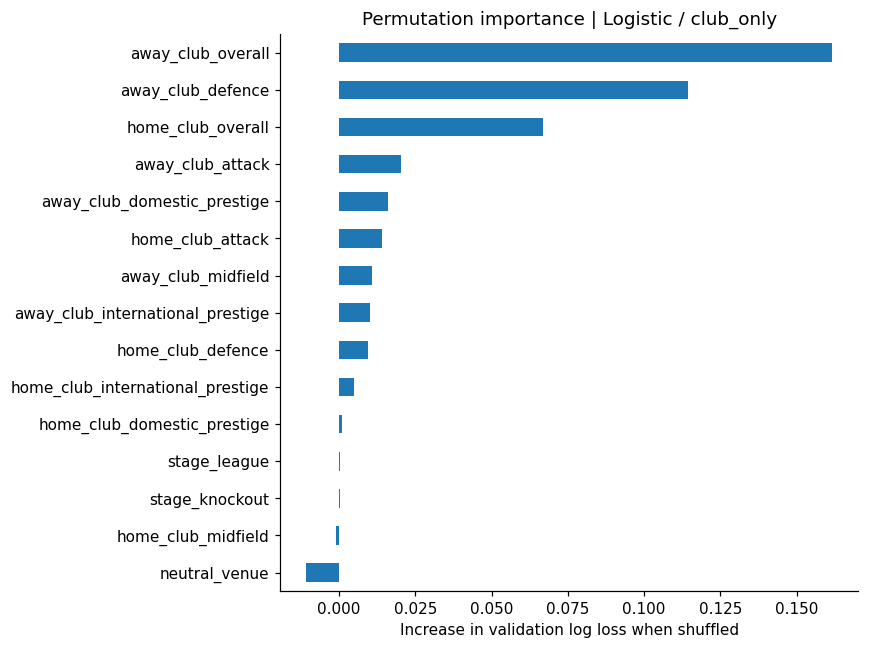

In [33]:
best=all_validation['wdl'].sort_values('log_loss').iloc[0]
bundle=joblib.load(RESULTS/'models'/f'wdl_{best.feature_set}_{best.model}.joblib')
Xval, val_meta=load_split(best.feature_set,'valid',bundle['scale'])
yval=encode_target('wdl',val_meta[TASKS['wdl']['label']])
r=permutation_importance(bundle['model'],Xval,yval,scoring='neg_log_loss',
    n_repeats=5,random_state=RANDOM_SEED,n_jobs=1)
imp=pd.Series(r.importances_mean,index=Xval.columns).sort_values(ascending=False)
display(imp.head(20).to_frame('permutation_importance'))
imp.to_csv(RESULTS/'wdl_permutation_importance.csv')
fig,ax=plt.subplots(figsize=(8,6));imp.head(20).sort_values().plot.barh(ax=ax)
ax.set_xlabel('Increase in validation log loss when shuffled')
ax.set_title(f'Permutation importance | {best.model} / {best.feature_set}')
fig.tight_layout();fig.savefig(RESULTS/'figures'/'wdl_permutation_importance.png',dpi=180)
plt.show()

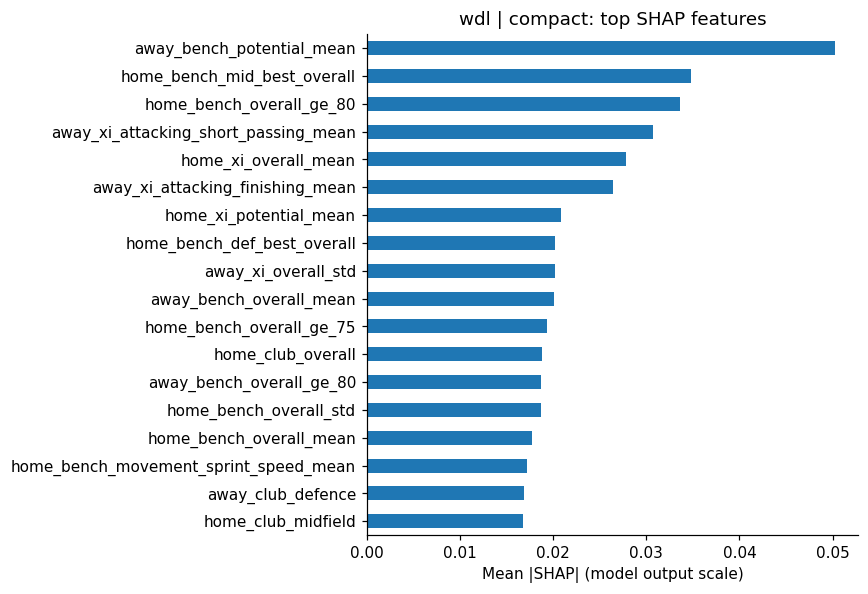

wdl SHAP model: CatBoostClassifier


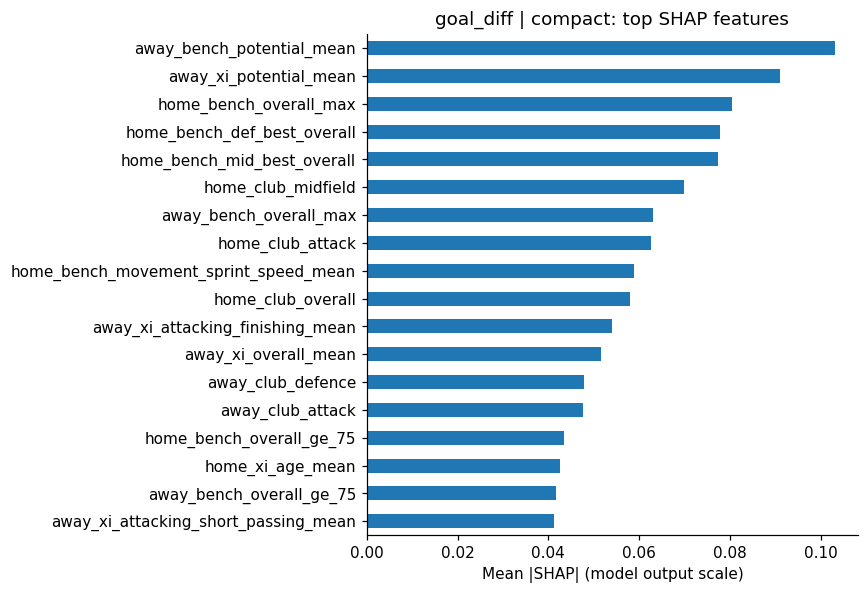

goal_diff SHAP model: CatBoostRegressor


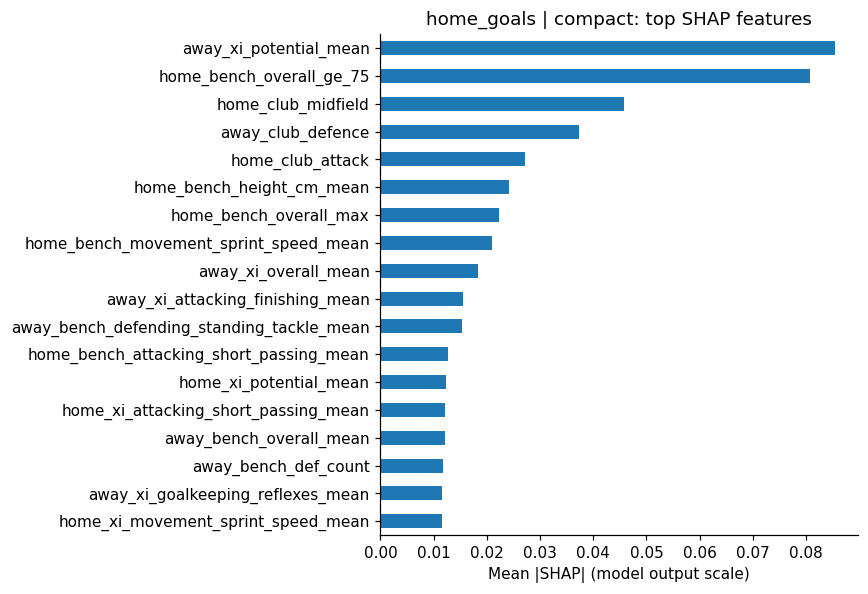

home_goals SHAP model: XGBRegressor


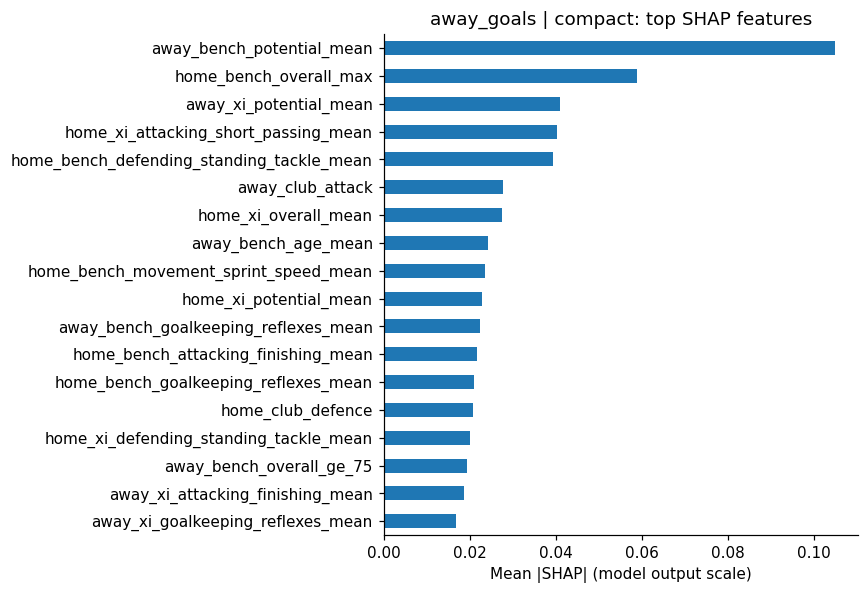

away_goals SHAP model: XGBRegressor


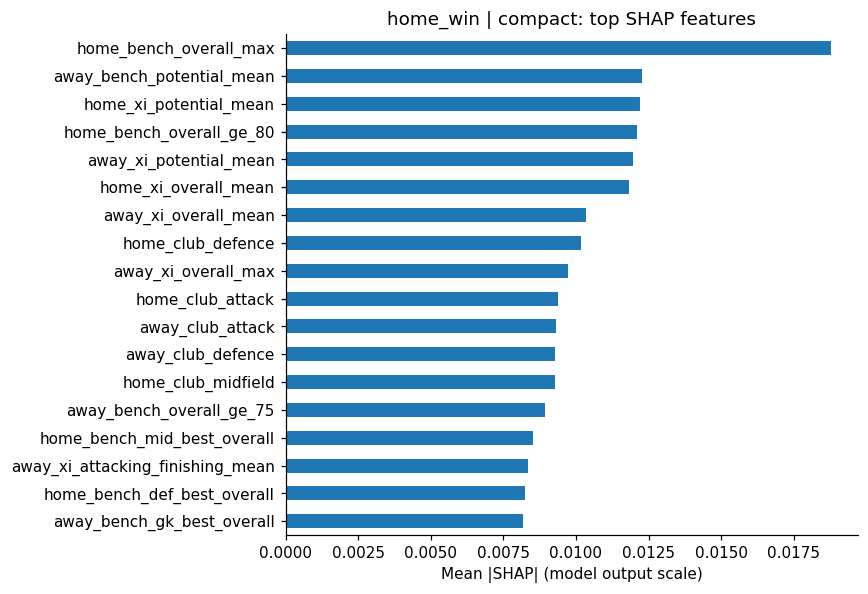

home_win SHAP model: RandomForestClassifier


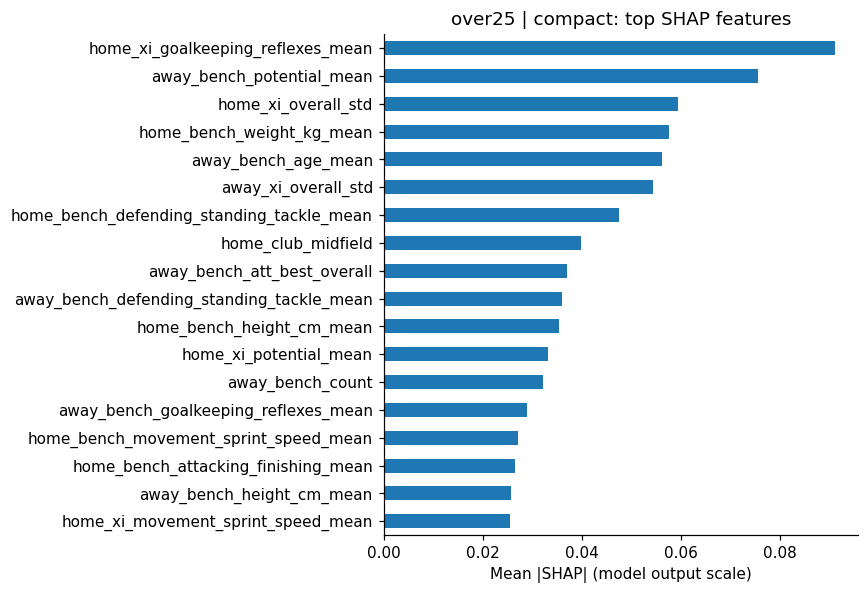

over25 SHAP model: CatBoostClassifier


In [35]:
import importlib.util
if importlib.util.find_spec('shap') is None:
    print('Install SHAP: python -m pip install shap')
else:
    import shap
    FEATURE_FOR_SHAP = 'compact'
    SAMPLE_SIZE = 80
    for task in TASKS:
        file=RESULTS/'models'/f'{task}_{FEATURE_FOR_SHAP}_best_tree.joblib'
        if not file.exists():
            continue  # Run the relevant task first.
        bundle=joblib.load(file)
        X,_=load_split(FEATURE_FOR_SHAP,'valid','tree')
        X=X.sample(min(SAMPLE_SIZE,len(X)),random_state=RANDOM_SEED)
        try:
            explainer=shap.TreeExplainer(bundle['model'])
            sv=explainer(X)
            values=np.asarray(sv.values)
            # Binary/regression: [rows, features]; multiclass: [rows, features, classes].
            # Average absolute contributions over samples and (if present) classes.
            if values.ndim==3:
                magnitudes=np.abs(values).mean(axis=(0,2))
            elif values.ndim==2:
                magnitudes=np.abs(values).mean(axis=0)
            else:
                raise ValueError(f'Unexpected SHAP shape: {values.shape}')
            result=pd.Series(magnitudes,index=X.columns).sort_values(ascending=False)
            result.rename('mean_abs_shap').to_csv(RESULTS/f'{task}_{FEATURE_FOR_SHAP}_shap.csv')
            fig,ax=plt.subplots(figsize=(8,5.5))
            result.head(18).sort_values().plot.barh(ax=ax)
            ax.set_xlabel('Mean |SHAP| (model output scale)')
            ax.set_title(f'{task} | {FEATURE_FOR_SHAP}: top SHAP features')
            fig.tight_layout()
            fig.savefig(RESULTS/'figures'/f'{task}_{FEATURE_FOR_SHAP}_shap.png',dpi=180)
            plt.show()
            print(task,'SHAP model:',type(bundle['model']).__name__)
        except Exception as e:
            print(f'{task}: SHAP unavailable for this model/version: {str(e)[:180]}')


### 3.6 Time-aware neural network

A sequential model is possible, but **do not use home club alone as the key**. Every match belongs in both clubs' histories; for a match on date *t*, only games before *t* are valid. Construct two ordered histories (home team and away team), encode each previous game with opponent strength, venue and observed result, then combine them with current EA ratings in a GRU/Transformer.

**Recommended order:** First report the tabular MLP as a neural baseline. After the six-task comparison, test a short-history GRU only if it adds value over Full/Compact; otherwise the extra complexity is hard to justify on ~1,425 historical matches.

For match simulation, prefer a model returning calibrated **W/D/L probabilities or home/away goal distributions**, not only hard winner labels.

# Part IV Unified match-outcome evaluation

**Goal:** compare models trained for different targets on the **same 90-minute W/D/L outcome**. Use **validation log loss** to select the winning approach; report accuracy and macro-F1 alongside it.

- **Three-way comparison:** Direct W/D/L, Goal-difference regression, Two-goal regression.
- **Binary-only comparison:** Home-win models (ROC-AUC, binary log loss); Over-2.5 does **not** predict W/D/L and stays separate.
- Thresholds or draw adjustments are selected on **Validation** only. **Test is not used to choose models or thresholds.**

Convert different prediction tasks into a common W/D/L evaluation framework for fair comparison. Goal Difference and Two Goals achieved slightly better probability predictions than Direct WDL, while Club Only remained the strongest feature set overall.

In [36]:
import numpy as np, pandas as pd, joblib, warnings
from pathlib import Path
from scipy.stats import norm, skellam
from sklearn.base import clone
from sklearn.metrics import (log_loss, accuracy_score, f1_score, roc_auc_score,
                             brier_score_loss, confusion_matrix)
from IPython.display import display


UNIFIED_DIR = RESULTS / 'unified_wdl'
UNIFIED_DIR.mkdir(parents=True, exist_ok=True)
(UNIFIED_DIR/'models').mkdir(exist_ok=True)

UNIFIED_FEATURES = ['club_only', 'compact', 'full_core']
EVALUATE_ALL_CANDIDATES = True
SEED = 42
DRAW_TAU_GRID = np.round(np.arange(0.1, 1.31, 0.1), 2)
DRAW_WEIGHT_GRID = [0.75, 1.0, 1.25, 1.5]

In [37]:
WDL_CLASSES = ['A', 'D', 'H']  # encoded as 0,1,2

def y_wdl(meta):
    return encode_target('wdl', meta['label_90min_wdl'])

def normalize_probs(p):
    p = np.asarray(p, dtype=float)
    p = np.maximum(p, 1e-9)
    return p / p.sum(axis=1, keepdims=True)

def wdl_metrics(y, probs):
    p = normalize_probs(probs)
    pred = np.argmax(p, axis=1)
    return dict(log_loss = log_loss(y, p, labels=[0,1,2]),
                accuracy = accuracy_score(y, pred),
                macro_f1 = f1_score(y, pred, labels=[0,1,2], average='macro', zero_division=0),
                home_win_auc = roc_auc_score((np.asarray(y)==2).astype(int), p[:,2])
                if len(np.unique(np.asarray(y) == 2)) == 2 else np.nan,
                home_win_brier = brier_score_loss((np.asarray(y) == 2).astype(int), p[:,2]))

def direct_probs(model, X):
    p = np.zeros((len(X), 3))
    for j, cl in enumerate(model.classes_):
        p[:, int(cl)] = model.predict_proba(X)[:,j]
    return normalize_probs(p)

def difference_probs(mu, sigma, tau):
    # Predicted goal difference ~ Normal(mu, sigma). A: below -tau, D: interval, H: above tau.
    mu = np.asarray(mu, dtype=float)
    sigma = max(float(sigma), 0.3)
    pa = norm.cdf((-tau-mu)/sigma)
    ph = norm.sf((tau-mu)/sigma)
    return normalize_probs(np.column_stack([pa,1-pa-ph,ph]))

def goals_probs(home_mu, away_mu, draw_weight=1.0):
    h = np.maximum(np.asarray(home_mu, dtype=float), 1e-4)
    a = np.maximum(np.asarray(away_mu, dtype=float), 1e-4)
    pa = skellam.cdf(-1,h,a)
    pd_ = skellam.pmf(0,h,a) * draw_weight
    ph = skellam.sf(0,h,a)
    return normalize_probs(np.column_stack([pa,pd_,ph]))

def candidate_models(task):
    models = make_models(task)
    if not EVALUATE_ALL_CANDIDATES:
        keep = {'Dummy','Logistic','Linear','Ridge','Poisson','XGBoost'}
        models = {k:v for k,v in models.items() if k in keep}
    return models

In [38]:
# Train and evaluate direct WDL + goal-difference candidates
all_rows = []
trained = {}

def fit_one(fs, task, model_name, estimator, scale):
    Xtr, mtr = load_split(fs, 'train', scale)
    Xva, mva = load_split(fs, 'valid', scale)
    ytr = encode_target(task, mtr[TASKS[task]['label']])
    fitted = clone(estimator)
    fitted.fit(Xtr, ytr)
    return fitted, Xtr, Xva, mtr, mva

for fs in UNIFIED_FEATURES:
    for task in ['wdl', 'goal_diff']:
        for name, (est,scale) in candidate_models(task).items():
            try:
                mdl, Xtr, Xva, mtr, mva = fit_one(fs,task,name,est,scale)
                if task == 'wdl':
                    prob = direct_probs(mdl, Xva)
                    extra = {'draw_tau':np.nan, 'sigma':np.nan}
                    route = 'Direct WDL'
                else:
                    train_resid = mtr[TASKS[task]['label']].to_numpy(float) - mdl.predict(Xtr)
                    sigma = max(np.std(train_resid,ddof=1), 0.3)
                    mu = mdl.predict(Xva)
                    options = [(log_loss(y_wdl(mva), difference_probs(mu,sigma,t),labels=[0,1,2]), t) for t in DRAW_TAU_GRID]
                    _, tau = min(options)
                    prob = difference_probs(mu, sigma, tau)
                    extra = {'draw_tau':tau, 'sigma':sigma}
                    route = 'Goal Difference'
                row={'route':route,'feature_set':fs,'model':name,
                     'scale':scale, **extra, **wdl_metrics(y_wdl(mva),prob)}
                all_rows.append(row)
                key = (route, fs, name)
                trained[key] = {'models':[mdl], 'scales':[scale], **extra}
            except Exception as exc:
                print('[skip]',fs,task,name,repr(exc)[:150])
    print('Done:',fs)

Done: club_only
Done: compact
Done: full_core


In [39]:
# Goal pairs
for fs in UNIFIED_FEATURES:
    preds, fitted = {}, {}
    valid_meta = load_split(fs,'valid')[1]
    for task in ['home_goals','away_goals']:
        for name, (est,scale) in candidate_models(task).items():
            try:
                mdl, _, Xva, _, _ = fit_one(fs, task, name, est, scale)
                preds[(task,name)] = np.maximum(np.asarray(mdl.predict(Xva),float), 1e-4)
                fitted[(task,name)] = (mdl,scale)
            except Exception as exc:
                print('[skip]',fs,task,name,repr(exc)[:150])
    n_pairs=0
    for hn in [k[1] for k in preds if k[0]=='home_goals']:
        for an in [k[1] for k in preds if k[0]=='away_goals']:
            h, a = preds[('home_goals',hn)], preds[('away_goals',an)]
            weights=[(log_loss(y_wdl(valid_meta),goals_probs(h,a,w),labels=[0,1,2]),w) for w in DRAW_WEIGHT_GRID]
            _, w = min(weights)
            prob = goals_probs(h, a, w)
            name = f'{hn} + {an}'
            row = {'route':'Two Goals','feature_set':fs,'model':name,
                 'scale':'mixed','draw_weight':w,**wdl_metrics(y_wdl(valid_meta),prob)}
            all_rows.append(row)
            trained[('Two Goals',fs,name)]={
                'models':[fitted[('home_goals',hn)][0],fitted[('away_goals',an)][0]],
                'scales':[fitted[('home_goals',hn)][1],fitted[('away_goals',an)][1]],
                'draw_weight':w}
            n_pairs += 1
    print(fs, '| goal-pairs evaluated:', n_pairs)


club_only | goal-pairs evaluated: 144
compact | goal-pairs evaluated: 144
full_core | goal-pairs evaluated: 144


In [40]:
# Compare and select on validation
val_table = pd.DataFrame(all_rows).sort_values('log_loss').reset_index(drop=True)
val_table.to_csv(UNIFIED_DIR/'validation_all_wdl.csv',index=False)
route_best = (val_table.sort_values('log_loss').drop_duplicates('route').reset_index(drop=True))
global_best = val_table.iloc[0]
route_best.to_csv(UNIFIED_DIR/'validation_route_winners.csv',index=False)
print('Best by route (Validation):')

display(route_best[['route','feature_set','model','log_loss','accuracy','macro_f1',
                    'home_win_auc','draw_tau','draw_weight']].round(4))
print('Overall winner (Validation):')
display(val_table.head(12)[['route','feature_set','model','log_loss','accuracy',
                             'macro_f1','draw_tau','draw_weight']].round(4))

Best by route (Validation):


,route,feature_set,model,log_loss,accuracy,macro_f1,home_win_auc,draw_tau,draw_weight
0,Goal Difference,club_only,Linear,0.9122,0.5723,0.4085,0.6929,0.4,NaN
1,Two Goals,club_only,Poisson + Poisson,0.9175,0.5607,0.3986,0.6853,NaN,0.75
2,Direct WDL,club_only,Logistic,0.9304,0.5723,0.4312,0.6939,NaN,NaN


Overall winner (Validation):


,route,feature_set,model,log_loss,accuracy,macro_f1,draw_tau,draw_weight
0,Goal Difference,club_only,Linear,0.9122,0.5723,0.4085,0.4,NaN
1,Goal Difference,club_only,Ridge,0.9137,0.5723,0.4085,0.4,NaN
2,Two Goals,club_only,Poisson + Poisson,0.9175,0.5607,0.3986,NaN,0.75
3,Two Goals,club_only,Poisson + Ridge,0.9180,0.5780,0.4139,NaN,0.75
4,Two Goals,club_only,Poisson + KNN,0.9185,0.6012,0.4302,NaN,0.75
5,Two Goals,compact,KNN + XGBoost,0.9191,0.5896,0.4200,NaN,0.75
6,Two Goals,club_only,Linear + KNN,0.9197,0.5954,0.4256,NaN,0.75
7,Two Goals,club_only,Linear + Poisson,0.9199,0.5780,0.4100,NaN,0.75
8,Two Goals,club_only,Linear + Ridge,0.9200,0.5665,0.4036,NaN,0.75
9,Two Goals,club_only,Ridge + KNN,0.9201,0.5954,0.4246,NaN,0.75


In [41]:
# Test evaluation and saved predictions
selected_keys=[]
for _, r in route_best.iterrows():
    selected_keys.append((r['route'], r['feature_set'], r['model']))
selected_keys = list(dict.fromkeys(selected_keys))

test_rows = []
for route, fs, name in selected_keys:
    pack = trained[(route, fs, name)]
    xmeta = load_split(fs,'test')[1]
    actual = y_wdl(xmeta)
    if route == 'Direct WDL':
        probs = direct_probs(pack['models'][0],load_split(fs,'test',pack['scales'][0])[0])
    elif route == 'Goal Difference':
        X = load_split(fs,'test',pack['scales'][0])[0]
        probs = difference_probs(pack['models'][0].predict(X),pack['sigma'],pack['draw_tau'])
    else:
        Xh = load_split(fs,'test',pack['scales'][0])[0]
        Xa = load_split(fs,'test',pack['scales'][1])[0]
        probs = goals_probs(pack['models'][0].predict(Xh),pack['models'][1].predict(Xa),pack['draw_weight'])

    scores = wdl_metrics(actual, probs)
    test_rows.append({'route':route,'feature_set':fs,'model':name,**scores})
    pred = xmeta[['match_id','season','home_team','away_team']].copy()
    pred['actual_wdl'] = np.asarray(WDL_CLASSES)[actual]
    pred[['p_away','p_draw','p_home']] = probs
    pred['pred_wdl'] = np.asarray(WDL_CLASSES)[probs.argmax(axis=1)]
    slug = route.lower().replace(' ','_')
    pred.to_csv(UNIFIED_DIR/f'test_predictions_{slug}.csv',index=False)
    joblib.dump({'route':route, 'feature_set':fs, 'model_name':name, **pack}, UNIFIED_DIR/'models'/f'{slug}_selected.joblib')

test_table=pd.DataFrame(test_rows)
display(test_table.round(4))
test_table.to_csv(UNIFIED_DIR/'test_route_winners.csv',index=False)

,route,feature_set,model,log_loss,accuracy,macro_f1,home_win_auc,home_win_brier
0,Goal Difference,club_only,Linear,0.9572,0.5460,0.3876,0.7275,0.2118
1,Two Goals,club_only,Poisson + Poisson,0.9530,0.5575,0.3948,0.7271,0.2131
2,Direct WDL,club_only,Logistic,0.9702,0.5632,0.4184,0.7345,0.2124


# Part V W/D/L diagnosis + Diff feature experiments

- **V-A:** Diagnose why W/D/L prediction is difficult, especially draws, using the Validation season.
- **V-B:** Compare Original, Difference Only, and Difference + selected average-strength features with the **same train/validation split and models**.
- Test data are not used for selecting new features or thresholds. All outputs are written to `model/results/diff_diagnostics/`.

Examine classification errors and tested whether representing team strength differences could improve predictions. All three approaches struggled to predict draws, while Diff + Level features slightly improved some models. These results highlight the need for better draw decisions and further model optimization.

## V-1 Diagnose current predictions

In [42]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             log_loss, accuracy_score, f1_score, roc_auc_score)
import warnings
from IPython.display import display

needed = ['load_split','make_models','route_best','trained','direct_probs',
          'difference_probs','goals_probs','wdl_metrics','y_wdl']
assert all(k in globals() for k in needed), f'Run Part III and IV first. Missing: {[k for k in needed if k not in globals()]}'
DIFF_DIR = RESULTS / 'diff_diagnostics'
DIFF_DIR.mkdir(parents=True, exist_ok=True)
WDL_LABELS = np.array(['A','D','H'])
RNG = 42


In [43]:
# Recover Validation predictions for each route winner

def best_route_probabilities(row, split='valid'):
    route, fs, name = row['route'], row['feature_set'], row['model']
    pack = trained[(route, fs, name)]
    meta = load_split(fs, split)[1]
    X = [load_split(fs, split, s)[0] for s in pack['scales']]
    if route == 'Direct WDL':
        p = direct_probs(pack['models'][0], X[0])
    elif route == 'Goal Difference':
        p = difference_probs(pack['models'][0].predict(X[0]),
                             pack['sigma'], pack['draw_tau'])
    else:
        p = goals_probs(pack['models'][0].predict(X[0]),
                        pack['models'][1].predict(X[1]), pack['draw_weight'])
    return meta, np.asarray(p)

validation_preds = {}
diagnosis_rows = []
for _, row in route_best.iterrows():
    route = row['route']
    meta, p = best_route_probabilities(row, 'valid')
    y = y_wdl(meta)
    pred = p.argmax(axis=1)
    validation_preds[route] = (meta, y, p)
    shares_actual = np.bincount(y, minlength=3) / len(y)
    shares_pred = np.bincount(pred, minlength=3) / len(y)
    recalls = np.diag(confusion_matrix(y,pred,labels=[0,1,2])) / np.maximum(1,np.bincount(y,minlength=3))
    diagnosis_rows.append(dict(route=route, n=len(y),
        actual_draw_pct=100*shares_actual[1], predicted_draw_pct=100*shares_pred[1],
        avg_p_draw=p[:,1].mean(), draw_recall=recalls[1],
        away_recall=recalls[0], home_recall=recalls[2],
        **wdl_metrics(y,p)))

diagnosis = pd.DataFrame(diagnosis_rows)
display(diagnosis.round(4))
diagnosis.to_csv(DIFF_DIR/'validation_draw_diagnosis.csv', index=False)


,route,n,actual_draw_pct,predicted_draw_pct,avg_p_draw,draw_recall,away_recall,home_recall,log_loss,accuracy,macro_f1,home_win_auc,home_win_brier
0,Goal Difference,173,15.6069,0.0000,0.1510,0.000,0.6207,0.7159,0.9122,0.5723,0.4085,0.6929,0.2246
1,Two Goals,173,15.6069,0.0000,0.1766,0.000,0.5862,0.7159,0.9175,0.5607,0.3986,0.6853,0.2258
2,Direct WDL,173,15.6069,1.1561,0.2148,0.037,0.6379,0.6932,0.9304,0.5723,0.4312,0.6939,0.2274


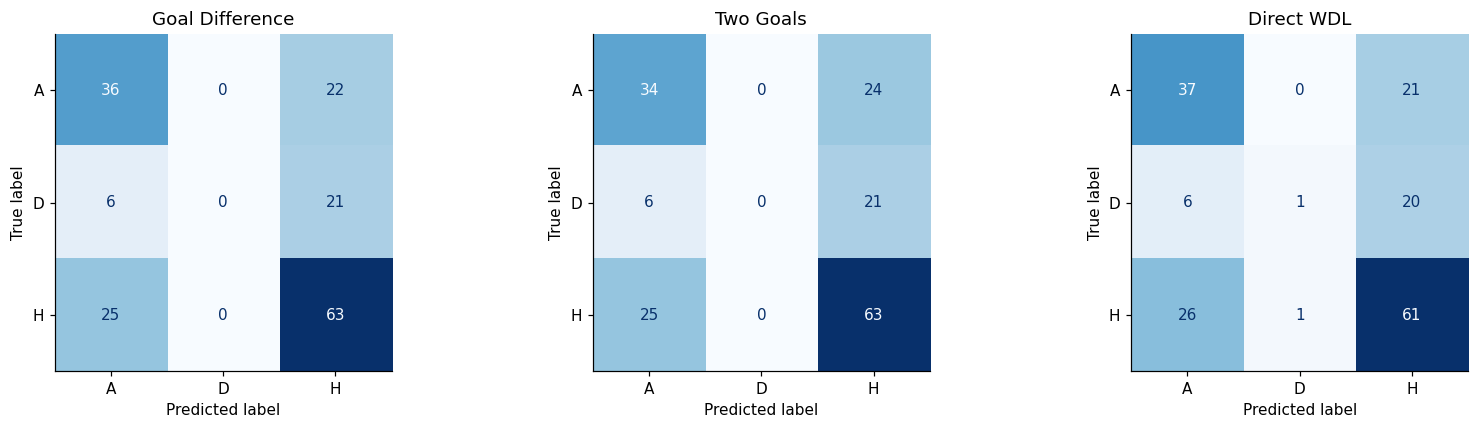


 Goal Difference | A=away win, D=draw, H=home win
              precision    recall  f1-score   support

           A      0.537     0.621     0.576        58
           D      0.000     0.000     0.000        27
           H      0.594     0.716     0.649        88

    accuracy                          0.572       173
   macro avg      0.377     0.446     0.408       173
weighted avg      0.482     0.572     0.523       173


 Two Goals | A=away win, D=draw, H=home win
              precision    recall  f1-score   support

           A      0.523     0.586     0.553        58
           D      0.000     0.000     0.000        27
           H      0.583     0.716     0.643        88

    accuracy                          0.561       173
   macro avg      0.369     0.434     0.399       173
weighted avg      0.472     0.561     0.512       173


 Direct WDL | A=away win, D=draw, H=home win
              precision    recall  f1-score   support

           A      0.536     0.638     0.5

In [44]:
# Three confusion matrices + class-specific scores
fig, axes = plt.subplots(1,len(validation_preds),figsize=(5*len(validation_preds),4))
axes=np.atleast_1d(axes)
for ax,(route, (_, y, p)) in zip(axes,validation_preds.items()):
    pred=p.argmax(axis=1)
    cm=confusion_matrix(y,pred,labels=[0,1,2])
    ConfusionMatrixDisplay(cm,display_labels=WDL_LABELS).plot(ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(route)
plt.tight_layout(); plt.savefig(DIFF_DIR/'validation_confusion_matrix.png',dpi=180);plt.show()
for route,(_,y,p) in validation_preds.items():
    print('\n',route,'| A=away win, D=draw, H=home win')
    print(classification_report(y,p.argmax(axis=1),labels=[0,1,2],target_names=WDL_LABELS,zero_division=0,digits=3))


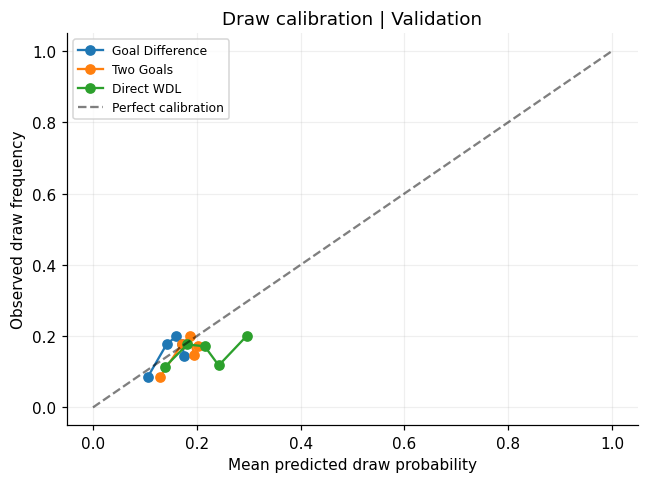

In [45]:
# Draw probability calibration
fig,ax=plt.subplots(figsize=(6,4.5))
records=[]
for route,(_,y,p) in validation_preds.items():
    d=pd.DataFrame({'p_draw':p[:,1],'draw':(y==1).astype(int)})
    # Equal-frequency bins prevent nearly empty calibration groups.
    d['bin']=pd.qcut(d['p_draw'].rank(method='first'),q=5,labels=False)
    g=d.groupby('bin').agg(mean_pred=('p_draw','mean'), observed=('draw','mean'),n=('draw','size'))
    ax.plot(g.mean_pred,g.observed,marker='o',label=route)
    records.append(g.assign(route=route).reset_index())
ax.plot([0,1],[0,1],'k--',alpha=.5,label='Perfect calibration')
ax.set(xlabel='Mean predicted draw probability',ylabel='Observed draw frequency',title='Draw calibration | Validation')
ax.legend(fontsize=8);ax.grid(alpha=.2);plt.tight_layout()
plt.savefig(DIFF_DIR/'validation_draw_calibration.png',dpi=180);plt.show()
pd.concat(records,ignore_index=True).to_csv(DIFF_DIR/'validation_draw_calibration.csv',index=False)


In [46]:
# Build paired feature schema and inspect it
FS_COMPARE = ['club_only','compact']
REPRESENTATIONS = ['original','diff_only','diff_level']
LEVEL_BASE = ['club_overall','xi_overall_mean','bench_overall_mean']
CONTEXT_COLS = ['neutral_venue','stage_league','stage_knockout']

def build_diff_features(X, representation):
    if representation == 'original':
        return X.copy()
    # A pair exists only if both teams have the same suffix.
    suffixes = [c[5:] for c in X.columns
                if c.startswith('home_') and 'away_'+c[5:] in X.columns]
    paired = {}
    for suffix in suffixes:
        paired['diff_'+suffix] = X['home_'+suffix].to_numpy(float) - X['away_'+suffix].to_numpy(float)
    out = pd.DataFrame(paired,index=X.index)
    if representation == 'diff_level':
        for suffix in LEVEL_BASE:
            if suffix in suffixes:
                out['level_'+suffix] = (X['home_'+suffix].to_numpy(float)+X['away_'+suffix].to_numpy(float))/2
    for c in CONTEXT_COLS:
        if c in X: out[c]=X[c].to_numpy()
    assert len(out.columns)==len(set(out.columns)) and np.isfinite(out.to_numpy(float)).all()
    return out

for fs in FS_COMPARE:
    X,_=load_split(fs,'train','tree')
    for rep in REPRESENTATIONS:
        z=build_diff_features(X,rep)
        print(f'{fs:10} | {rep:11} | {X.shape[1]:3} -> {z.shape[1]:3} columns')
    if fs=='compact':
        print('Example difference columns:',list(build_diff_features(X,'diff_only').columns[:12]))


club_only  | original    |  15 ->  15 columns
club_only  | diff_only   |  15 ->   9 columns
club_only  | diff_level  |  15 ->  10 columns
compact    | original    |  93 ->  93 columns
compact    | diff_only   |  93 ->  48 columns
compact    | diff_level  |  93 ->  51 columns
Example difference columns: ['diff_xi_fill_count', 'diff_squad_count', 'diff_bench_count', 'diff_xi_left_foot_count', 'diff_club_overall', 'diff_club_attack', 'diff_club_midfield', 'diff_club_defence', 'diff_club_domestic_prestige', 'diff_club_international_prestige', 'diff_xi_overall_mean', 'diff_xi_potential_mean']


### V-2 model comparisons

Use the same model settings and data splits to isolate the benefit of the feature representation. Compare the three main W/D/L routes with lightweight, interpretable candidates:

- **Direct W/D/L:** Logistic + XGBoost.
- **Goal difference:** Linear and Ridge; optimize `draw_tau` on Validation.
- **Two goals:** Poisson + Poisson; optimize `draw_weight` on Validation.

Select and rank by Validation W/D/L Log Loss.

In [47]:
# prepare representations
from sklearn.preprocessing import StandardScaler
FEATURE_CACHE={}

def matrices_for(fs,rep):
    key=(fs,rep)
    if key not in FEATURE_CACHE:
        tree={split:build_diff_features(load_split(fs,split,'tree')[0],rep)
              for split in ['train','valid']}
        assert tree['train'].columns.equals(tree['valid'].columns)
        scaler=StandardScaler().fit(tree['train'])
        scaled={split:pd.DataFrame(scaler.transform(df),columns=df.columns,index=df.index)
                for split,df in tree.items()}
        FEATURE_CACHE[key]={'tree':tree,'scaled':scaled,'scaler':scaler}
    return FEATURE_CACHE[key]

RUN_XGB_DIFF = True
DRAW_TAUS = np.round(np.arange(0.2,1.41,.1),2)
DRAW_WEIGHTS = [0.65,0.75,0.85,1.0,1.15,1.3]

In [48]:
# Train the three routes across representations

def fit_diff_model(task,name,bank, fs):
    options = make_models(task)
    if name not in options: return None
    template, scale = options[name]
    y = encode_target(task,load_split(fs,'train')[1][TASKS[task]['label']])
    model = clone(template)
    model.fit(bank[scale]['train'],y)
    return model,scale

comparison = []
for fs in FS_COMPARE:
    meta_valid = load_split(fs,'valid')[1]
    yvalid = y_wdl(meta_valid)
    for rep in REPRESENTATIONS:
        bank = matrices_for(fs,rep)
        ncols = bank['tree']['train'].shape[1]
        direct_names = ['Logistic'] + (['XGBoost'] if RUN_XGB_DIFF else [])
        for name in direct_names:
            res = fit_diff_model('wdl',name,bank,fs)
            if res is None: 
                continue
            model, scale = res
            p = direct_probs(model, bank[scale]['valid'])
            comparison.append(dict(feature_set=fs, representation=rep, n_features=ncols,
                route='Direct WDL', model=name, draw_tau=np.nan, draw_weight=np.nan, **wdl_metrics(yvalid,p)))
        for name in ['Linear','Ridge']:
            res = fit_diff_model('goal_diff',name,bank,fs)
            if res is None: 
                continue
            model, scale = res
            Xtr = bank[scale]['train']
            Xva = bank[scale]['valid']
            ytr = encode_target('goal_diff',load_split(fs,'train')[1][TASKS['goal_diff']['label']])

            sigma = max(float(np.std(ytr-model.predict(Xtr),ddof=1)),.3)
            mu = model.predict(Xva)
            tau = min(DRAW_TAUS,key=lambda t:log_loss(yvalid,difference_probs(mu,sigma,t),labels=[0,1,2]))
            p = difference_probs(mu,sigma,tau)
            comparison.append(dict(feature_set=fs,representation=rep,n_features=ncols, 
                                   route='Goal Difference',model=name,draw_tau=tau,draw_weight=np.nan, **wdl_metrics(yvalid,p)))
        home = fit_diff_model('home_goals','Poisson',bank,fs)
        away = fit_diff_model('away_goals','Poisson',bank,fs)
        if home is not None and away is not None:
            mh, sh = home
            ma, sa = away
            h = mh.predict(bank[sh]['valid']);a=ma.predict(bank[sa]['valid'])
            w = min(DRAW_WEIGHTS,key=lambda weight:log_loss(yvalid,goals_probs(h,a,weight),labels=[0,1,2]))
            p = goals_probs(h,a,w)
            comparison.append(dict(feature_set=fs,representation=rep,n_features=ncols,
                route='Two Goals', model='Poisson + Poisson', draw_tau=np.nan, draw_weight=w, **wdl_metrics(yvalid,p)))
        print('Done:',fs,rep)

comparison=pd.DataFrame(comparison).sort_values('log_loss').reset_index(drop=True)
comparison.to_csv(DIFF_DIR/'diff_validation_all.csv',index=False)
display(comparison[['feature_set','representation','n_features','route','model',
                    'log_loss','accuracy','macro_f1','home_win_auc','draw_tau','draw_weight']].round(4))


Done: club_only original
Done: club_only diff_only
Done: club_only diff_level
Done: compact original
Done: compact diff_only
Done: compact diff_level


,feature_set,representation,n_features,route,model,log_loss,accuracy,macro_f1,home_win_auc,draw_tau,draw_weight
0,club_only,diff_level,10,Two Goals,Poisson + Poisson,0.9111,0.5549,0.3948,0.6901,NaN,0.65
1,club_only,original,15,Goal Difference,Linear,0.9122,0.5723,0.4085,0.6929,0.4,NaN
2,club_only,diff_only,9,Two Goals,Poisson + Poisson,0.9124,0.5607,0.3986,0.6896,NaN,0.65
3,club_only,diff_level,10,Goal Difference,Ridge,0.9135,0.5665,0.4046,0.6878,0.4,NaN
4,club_only,original,15,Goal Difference,Ridge,0.9137,0.5723,0.4085,0.6904,0.4,NaN
5,club_only,diff_level,10,Goal Difference,Linear,0.9137,0.5780,0.4124,0.6876,0.4,NaN
6,club_only,diff_only,9,Goal Difference,Ridge,0.9156,0.5665,0.4036,0.6864,0.4,NaN
7,club_only,original,15,Two Goals,Poisson + Poisson,0.9160,0.5607,0.3986,0.6852,NaN,0.65
8,club_only,diff_only,9,Goal Difference,Linear,0.9160,0.5549,0.3935,0.6850,0.4,NaN
9,club_only,diff_level,10,Direct WDL,Logistic,0.9278,0.5723,0.4110,0.6908,NaN,NaN


representation               diff_level  diff_only  original  \
feature_set route                                              
club_only   Direct WDL           0.9278     0.9305    0.9304   
            Goal Difference      0.9135     0.9156    0.9122   
            Two Goals            0.9111     0.9124    0.9160   
compact     Direct WDL           0.9780     0.9761    0.9678   
            Goal Difference      0.9561     0.9585    0.9713   
            Two Goals            0.9301     0.9314    0.9355   

representation              best_representation  
feature_set route                                
club_only   Direct WDL               diff_level  
            Goal Difference            original  
            Two Goals                diff_level  
compact     Direct WDL                 original  
            Goal Difference          diff_level  
            Two Goals                diff_level

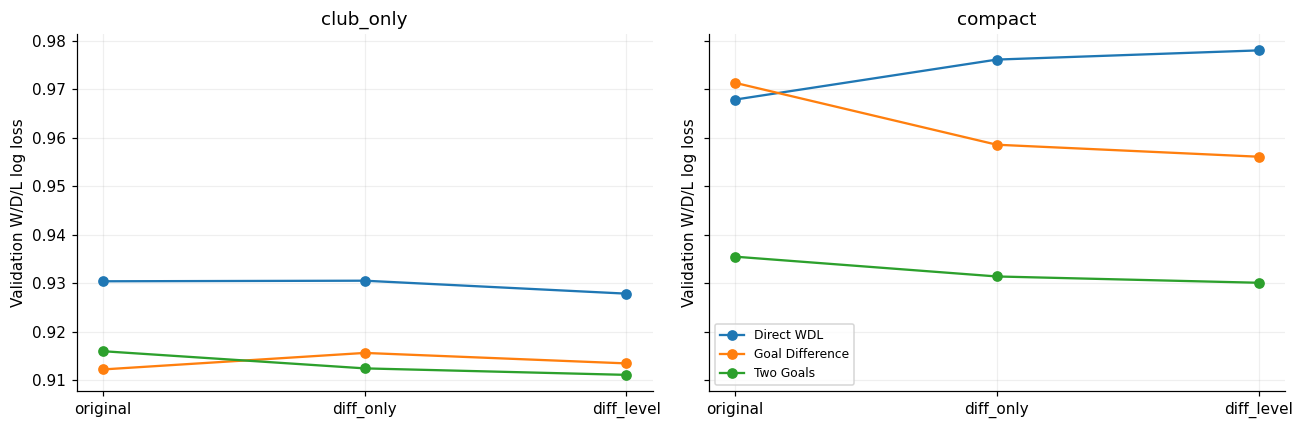

In [49]:
# comparison: best model per route and feature set
winners = (comparison.sort_values('log_loss').drop_duplicates(['feature_set','representation','route']))
winners.to_csv(DIFF_DIR/'diff_validation_winners.csv',index=False)
summary = winners.pivot_table(index=['feature_set','route'],columns='representation',values='log_loss')
summary['best_representation'] = summary[['original','diff_only','diff_level']].idxmin(axis=1)
display(summary.round(4))

fig, axes = plt.subplots(1,len(FS_COMPARE),figsize=(12,4),sharey=True)
for ax, fs in zip(np.atleast_1d(axes),FS_COMPARE):
    tmp=winners[winners.feature_set == fs]
    for route, g in tmp.groupby('route'):
        gg = g.set_index('representation').reindex(REPRESENTATIONS)
        ax.plot(REPRESENTATIONS, gg.log_loss, marker='o', label=route)
    ax.set_title(fs)
    ax.set_ylabel('Validation W/D/L log loss')
    ax.grid(alpha=.2)
axes[-1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(DIFF_DIR/'diff_validation_comparison.png',dpi=180)
plt.show()


In [50]:
# Compare Train / Validation / Test performance for all trained models
rows = []

for (route, fs, name), pack in trained.items():
    result = {'route': route, 'feature_set': fs, 'model': name}
    for split in ['train', 'valid', 'test']:
        meta = load_split(fs, split)[1]
        y = y_wdl(meta)

        if route == 'Direct WDL':
            X = load_split(fs, split, pack['scales'][0])[0]
            probs = direct_probs(pack['models'][0], X)

        elif route == 'Goal Difference':
            X = load_split(fs, split, pack['scales'][0])[0]
            mu = pack['models'][0].predict(X)
            probs = difference_probs(mu, pack['sigma'], pack['draw_tau'])

        else:  # Two Goals
            Xh = load_split(fs, split, pack['scales'][0])[0]
            Xa = load_split(fs, split, pack['scales'][1])[0]
            h = pack['models'][0].predict(Xh)
            a = pack['models'][1].predict(Xa)
            probs = goals_probs(h, a, pack['draw_weight'])

        metrics = wdl_metrics(y, probs)

        for metric in ['accuracy', 'macro_f1', 'home_win_auc', 'log_loss']:
            result[f'{split}_{metric}'] = metrics[metric]

    result['accuracy_gap'] = result['train_accuracy'] - result['valid_accuracy']
    result['auc_gap'] = result['train_home_win_auc'] - result['valid_home_win_auc']

    rows.append(result)

comparison = pd.DataFrame(rows)

# Rank models using Validation Accuracy
comparison = comparison.sort_values('valid_accuracy', ascending=False).reset_index(drop=True)

cols = [
    'route', 'feature_set', 'model',
    'train_accuracy', 'valid_accuracy', 'test_accuracy',
    'accuracy_gap',
    'train_home_win_auc', 'valid_home_win_auc', 'test_home_win_auc',
    'auc_gap'
]

display(comparison[cols].head(30).round(4))

# Best model from each route and feature set
best_by_group = comparison.drop_duplicates(['route', 'feature_set'])
print("Best models by route and feature set:")
display(best_by_group[cols].round(4))
comparison.to_csv('model/results/train_valid_test_comparison.csv', index=False)

,route,feature_set,model,train_accuracy,valid_accuracy,test_accuracy,accuracy_gap,train_home_win_auc,valid_home_win_auc,test_home_win_auc,auc_gap
0,Two Goals,compact,KNN + HistGB,0.8343,0.6301,0.5632,0.2042,0.9932,0.6783,0.7032,0.3148
1,Two Goals,club_only,Poisson + KNN,0.6952,0.6012,0.5690,0.0941,0.8693,0.6846,0.7285,0.1846
2,Two Goals,club_only,Linear + KNN,0.6915,0.5954,0.5402,0.0962,0.8669,0.6900,0.7293,0.1770
3,Two Goals,compact,KNN + DecisionTree,0.7090,0.5954,0.5402,0.1136,0.9291,0.6579,0.6927,0.2712
4,Goal Difference,club_only,KNN,0.7882,0.5954,0.5805,0.1928,1.0000,0.6682,0.7429,0.3318
5,Two Goals,full_core,MLP + DecisionTree,0.6676,0.5954,0.5690,0.0722,0.8707,0.6647,0.7133,0.2060
6,Two Goals,club_only,Ridge + KNN,0.6971,0.5954,0.5460,0.1017,0.8678,0.6896,0.7285,0.1782
7,Two Goals,club_only,RandomForest + HistGB,0.6796,0.5954,0.5977,0.0842,0.8951,0.6459,0.7256,0.2492
8,Two Goals,club_only,XGBoost + KNN,0.7145,0.5954,0.5690,0.1192,0.8891,0.6644,0.7326,0.2247
9,Two Goals,club_only,KNN + KNN,0.8481,0.5954,0.5805,0.2527,1.0000,0.6689,0.7468,0.3311


Best models by route and feature set:


,route,feature_set,model,train_accuracy,valid_accuracy,test_accuracy,accuracy_gap,train_home_win_auc,valid_home_win_auc,test_home_win_auc,auc_gap
0,Two Goals,compact,KNN + HistGB,0.8343,0.6301,0.5632,0.2042,0.9932,0.6783,0.7032,0.3148
1,Two Goals,club_only,Poisson + KNN,0.6952,0.6012,0.5690,0.0941,0.8693,0.6846,0.7285,0.1846
4,Goal Difference,club_only,KNN,0.7882,0.5954,0.5805,0.1928,1.0000,0.6682,0.7429,0.3318
5,Two Goals,full_core,MLP + DecisionTree,0.6676,0.5954,0.5690,0.0722,0.8707,0.6647,0.7133,0.2060
32,Direct WDL,club_only,MLP,0.5792,0.5780,0.5690,0.0012,0.7655,0.6834,0.7336,0.0821
38,Goal Difference,full_core,MLP,0.6703,0.5780,0.5862,0.0923,0.8727,0.6584,0.7275,0.2143
52,Goal Difference,compact,KNN,0.7882,0.5723,0.5920,0.2160,1.0000,0.6678,0.7361,0.3322
62,Direct WDL,compact,KNN,1.0000,0.5723,0.5920,0.4277,1.0000,0.6711,0.7258,0.3289
104,Direct WDL,full_core,MLP,0.9254,0.5665,0.5460,0.3589,0.9748,0.6922,0.6915,0.2826


# Part VI Attempts on model and features 11.24

**Draw Threshold Optimization and Multiclass ROC**

Adjusting the draw threshold improved Macro-F1 and Draw Recall across all three approaches. Direct WDL achieved the best balance, improving test accuracy from 56.3% to 57.5% while also improving draw detection.

Multiclass ROC analysis showed that the models distinguish home and away wins reasonably well, but struggle to identify draws (Draw AUC ≈ 0.55). This suggests that better features and models may be needed rather than relying on threshold adjustments alone.

In [51]:
# Optimize draw threshold on Validation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score,
    recall_score, roc_auc_score, roc_curve, auc,
    confusion_matrix, ConfusionMatrixDisplay
)

# A=0, D=1, H=2
CLASSES = ['A', 'D', 'H']
THRESHOLDS = np.linspace(0.05, 0.50, 91)

def predict_with_draw_threshold(probs, threshold):
    probs = np.asarray(probs)
    pred = np.where(probs[:, 2] >= probs[:, 0], 2, 0)
    pred[probs[:, 1] >= threshold] = 1
    return pred

def evaluate_predictions(y, pred):
    return {
        'accuracy': accuracy_score(y, pred),
        'macro_f1': f1_score(
            y, pred, average='macro', zero_division=0
        ),
        'draw_precision': precision_score(
            y == 1, pred == 1, zero_division=0
        ),
        'draw_recall': recall_score(
            y == 1, pred == 1, zero_division=0
        ),
        'pred_draw_pct': np.mean(pred == 1) * 100
    }

threshold_results = []
best_thresholds = {}

for route, (_, y, probs) in validation_preds.items():
    baseline_pred = probs.argmax(axis=1)
    baseline = evaluate_predictions(y, baseline_pred)

    for threshold in THRESHOLDS:
        pred = predict_with_draw_threshold(probs, threshold)
        metrics = evaluate_predictions(y, pred)

        threshold_results.append({
            'route': route,
            'threshold': threshold,
            **metrics
        })

    df_route = pd.DataFrame([r for r in threshold_results if r['route'] == route])

    # Maximize Macro-F1, then Accuracy
    best = df_route.sort_values(['macro_f1', 'accuracy'], ascending=False).iloc[0]
    best_thresholds[route] = float(best['threshold'])

    print(f"\n{route}")
    print(f"Original: Accuracy={baseline['accuracy']:.3f}, "
          f"Macro-F1={baseline['macro_f1']:.3f}, "
          f"Draw Recall={baseline['draw_recall']:.3f}")

    print(f"Optimized: Threshold={best['threshold']:.3f}, "
          f"Accuracy={best['accuracy']:.3f}, "
          f"Macro-F1={best['macro_f1']:.3f}, "
          f"Draw Recall={best['draw_recall']:.3f}")

threshold_df = pd.DataFrame(threshold_results)


Goal Difference
Original: Accuracy=0.572, Macro-F1=0.408, Draw Recall=0.000
Optimized: Threshold=0.170, Accuracy=0.486, Macro-F1=0.446, Draw Recall=0.333

Two Goals
Original: Accuracy=0.561, Macro-F1=0.399, Draw Recall=0.000
Optimized: Threshold=0.195, Accuracy=0.497, Macro-F1=0.448, Draw Recall=0.333

Direct WDL
Original: Accuracy=0.572, Macro-F1=0.431, Draw Recall=0.037
Optimized: Threshold=0.290, Accuracy=0.566, Macro-F1=0.468, Draw Recall=0.148


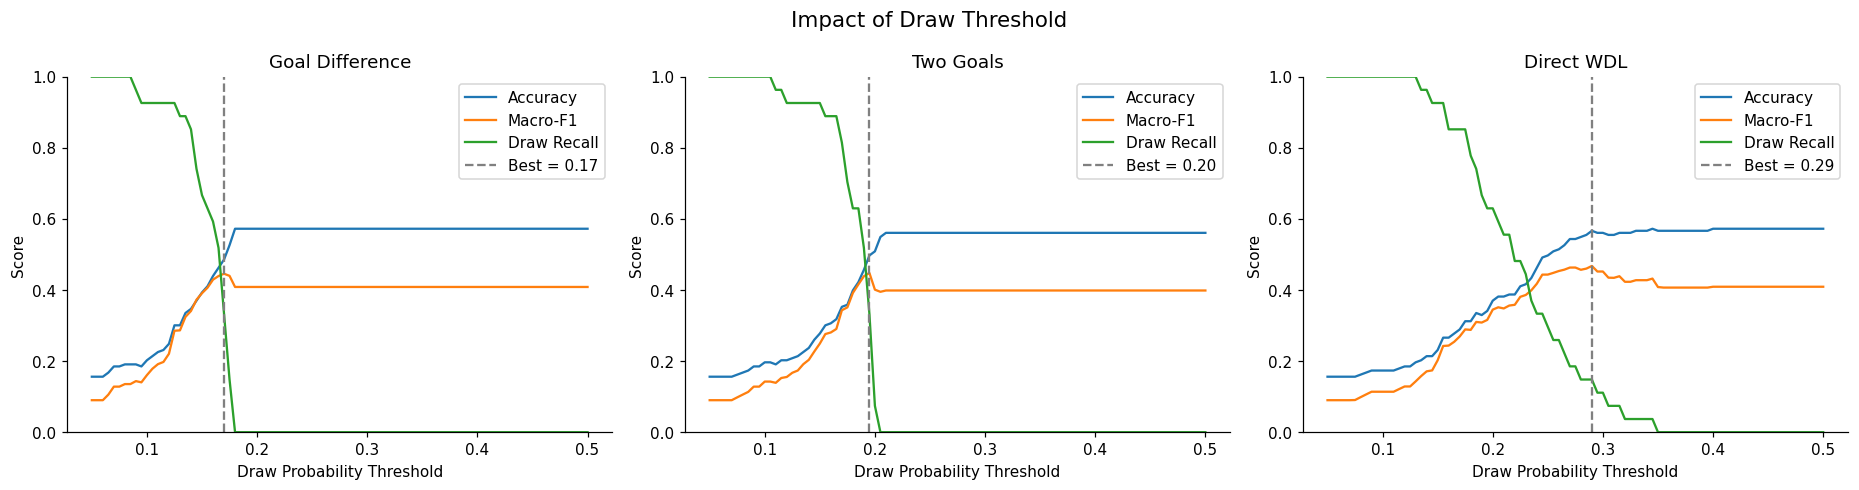

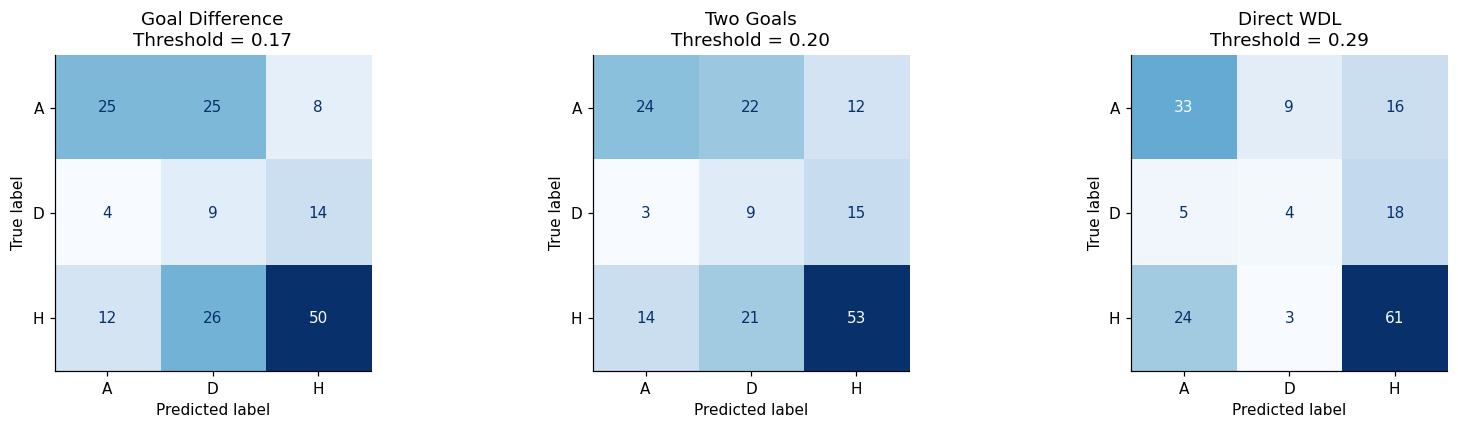

In [52]:
# Threshold curves and confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for ax, route in zip(axes, validation_preds):
    df = threshold_df[threshold_df['route'] == route]
    best_t = best_thresholds[route]

    ax.plot(df['threshold'], df['accuracy'], label='Accuracy')
    ax.plot(df['threshold'], df['macro_f1'], label='Macro-F1')
    ax.plot(df['threshold'], df['draw_recall'], label='Draw Recall')

    ax.axvline(best_t, color='gray', linestyle='--',
               label=f'Best = {best_t:.2f}')

    ax.set_title(route)
    ax.set_xlabel('Draw Probability Threshold')
    ax.set_ylabel('Score')
    ax.set_ylim(0, 1)
    ax.legend()

plt.suptitle('Impact of Draw Threshold', fontsize=14)
plt.tight_layout()
plt.show()


# Confusion matrices after optimization
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (route, (_, y, probs)) in zip(axes, validation_preds.items()):
    pred = predict_with_draw_threshold(probs, best_thresholds[route])
    cm = confusion_matrix(y, pred, labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{route}\nThreshold = {best_thresholds[route]:.2f}')

plt.tight_layout()
plt.show()

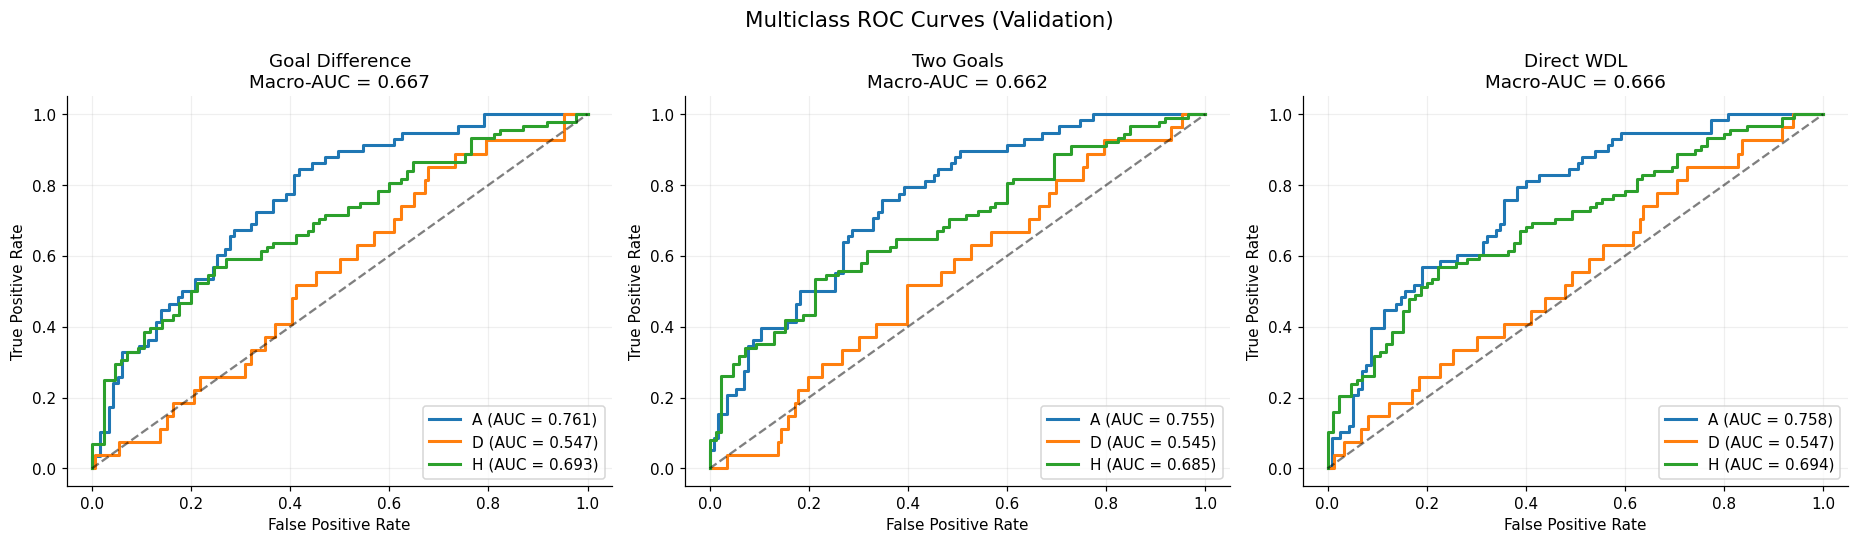

,route,away_auc,draw_auc,home_auc,macro_auc
0,Goal Difference,0.7612,0.5472,0.6929,0.6671
1,Two Goals,0.7550,0.5452,0.6853,0.6618
2,Direct WDL,0.7579,0.5474,0.6939,0.6664


In [53]:
# Multiclass ROC-AUC (One-vs-Rest)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
auc_rows = []

for ax, (route, (_, y, probs)) in zip(axes, validation_preds.items()):
    class_aucs = []
    for i, label in enumerate(CLASSES):
        y_binary = (y == i).astype(int)
        fpr, tpr, _ = roc_curve(y_binary, probs[:, i])
        class_auc = auc(fpr, tpr)
        class_aucs.append(class_auc)

        ax.plot(fpr, tpr, lw=2, label=f'{label} (AUC = {class_auc:.3f})')
    macro_auc = np.mean(class_aucs)

    auc_rows.append({
        'route': route,
        'away_auc': class_aucs[0],
        'draw_auc': class_aucs[1],
        'home_auc': class_aucs[2],
        'macro_auc': macro_auc
    })

    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    ax.set_title(f'{route}\nMacro-AUC = {macro_auc:.3f}')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.legend(loc='lower right')
    ax.grid(alpha=0.2)

plt.suptitle('Multiclass ROC Curves (Validation)', fontsize=14)
plt.tight_layout()
plt.show()

auc_table = pd.DataFrame(auc_rows)
display(auc_table.round(4))

In [54]:
# Final comparison on Test
test_rows = []

for _, row in route_best.iterrows():
    route = row['route']
    meta, probs = best_route_probabilities(row, 'test')
    y = y_wdl(meta)

    original_pred = probs.argmax(axis=1)
    optimized_pred = predict_with_draw_threshold(probs, best_thresholds[route])

    for name, pred in [
        ('Original', original_pred),
        ('Optimized', optimized_pred)
    ]:
        test_rows.append({
            'route': route,
            'decision_rule': name,
            **evaluate_predictions(y, pred)
        })

test_comparison = pd.DataFrame(test_rows)

display(test_comparison.sort_values(['route', 'decision_rule']).round(4))


from pathlib import Path
out_dir = Path('model/results/threshold_optimization')
out_dir.mkdir(parents=True, exist_ok=True)

threshold_df.to_csv(out_dir / 'threshold_search.csv', index=False)
auc_table.to_csv(out_dir / 'multiclass_auc.csv', index=False)
test_comparison.to_csv(out_dir / 'test_comparison.csv', index=False)

,route,decision_rule,accuracy,macro_f1,draw_precision,draw_recall,pred_draw_pct
5,Direct WDL,Optimized,0.5747,0.4722,0.5714,0.1290,4.0230
4,Direct WDL,Original,0.5632,0.4184,1.0000,0.0323,0.5747
1,Goal Difference,Optimized,0.5172,0.4771,0.2069,0.3871,33.3333
0,Goal Difference,Original,0.5460,0.3876,0.0000,0.0000,0.0000
3,Two Goals,Optimized,0.5287,0.4776,0.2449,0.3871,28.1609
2,Two Goals,Original,0.5575,0.3948,0.0000,0.0000,0.0000


### Preliminary Player-Level Feature Analysis

Examine whether player-level features provide additional predictive value beyond club ratings through correlation analysis, feature-set comparisons, and permutation importance.

| Analysis | Key Findings |
|---|---|
| Partial Correlation | Top 11 average age (−0.129) and potential (0.122) showed the strongest additional correlations with goal difference after controlling for club ratings. |
| Feature Set Comparison | Club Only achieved the highest Macro-AUC (0.670), followed by Player Aggregates Only (0.626). Individual Players Only performed worse (0.570), suggesting that aggregated features are more effective than directly using hundreds of player attributes. |
| Position Importance | MID (0.031) and ATT (0.028) showed the largest positive contributions to Macro-AUC, while DEF had a smaller contribution and GK showed no positive contribution in the current model. |

**Conclusion:** Player-level information shows some predictive potential, but adding raw individual attributes does not consistently improve performance beyond club ratings. Next step is to examine specific attributes within each position group and construct more meaningful position-aware statistical features.

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

df = pd.read_csv('data/match_dataset/matches_full.csv')

club_cols = [
    f'{side}_club_{attr}'
    for side in ['home', 'away']
    for attr in [
        'overall', 'attack', 'midfield', 'defence',
        'domestic_prestige', 'international_prestige'
    ]
] + ['neutral_venue', 'stage_league', 'stage_knockout']

aggregate_cols = [
    c for c in df.columns
    if c.startswith(('home_xi_', 'away_xi_',
                     'home_bench_', 'away_bench_'))
]

slots = (
    ['gk1']
    + [f'def{i}' for i in range(1, 5)]
    + [f'mid{i}' for i in range(1, 4)]
    + [f'att{i}' for i in range(1, 4)]
)

individual_cols = [
    c for c in df.columns
    if any(
        c.startswith(f'{side}_{slot}_')
        for side in ['home', 'away']
        for slot in slots
    )
]

# Same season split as previous experiments
train_mask = df['season'] <= '2023-24'
valid_mask = df['season'] == '2024-25'

feature_sets = {
    'Club Only': club_cols,
    'Player Aggregates Only': aggregate_cols,
    'Individual Players Only': individual_cols,
    'Club + Aggregates': club_cols + aggregate_cols,
    'Club + Individual': club_cols + individual_cols,
    'All Features': club_cols + aggregate_cols + individual_cols
}

for name, cols in feature_sets.items():
    print(f'{name}: {len(cols)} features')


Club Only: 15 features
Player Aggregates Only: 76 features
Individual Players Only: 704 features
Club + Aggregates: 91 features
Club + Individual: 719 features
All Features: 795 features


,feature,raw_corr,partial_corr,abs_partial_corr
5,xi_age_mean,0.043,-0.129,0.129
4,xi_potential_mean,0.512,0.122,0.122
1,bench_count,0.167,-0.073,0.073
17,bench_age_mean,-0.008,-0.070,0.070
16,bench_potential_mean,0.452,0.061,0.061
14,xi_overall_std,0.142,0.058,0.058
25,bench_overall_max,0.496,0.057,0.057
29,bench_overall_ge_85,0.267,0.051,0.051
10,xi_attacking_short_passing_mean,0.464,0.048,0.048
36,bench_att_count,0.022,-0.041,0.041


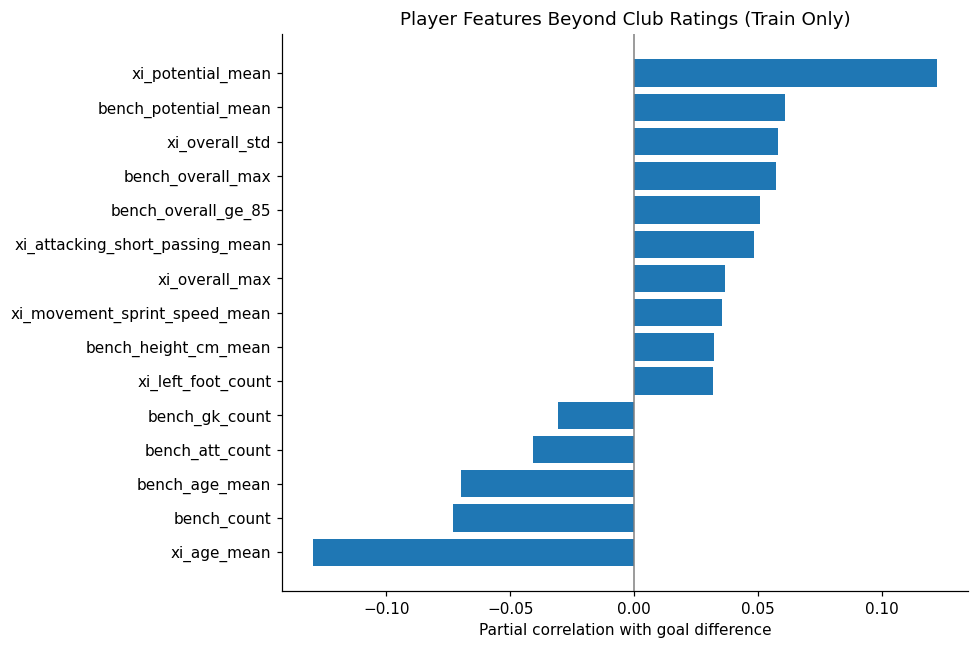

In [56]:
# explore player attributes beyond club ratings
from scipy.stats import pearsonr

train = df.loc[train_mask].copy()
goal_diff = train['label_90min_goal_diff'].astype(float)
controls = train[club_cols].apply(pd.to_numeric, errors='coerce')
controls = controls.fillna(controls.median()).fillna(0)

control_model = LinearRegression().fit(controls, goal_diff)
goal_residual = goal_diff - control_model.predict(controls)

results = []
for h in aggregate_cols:
    if not h.startswith('home_'):
        continue
    a = 'away_' + h[5:]
    if a not in train.columns:
        continue

    x = pd.to_numeric(train[h], errors='coerce')
    z = pd.to_numeric(train[a], errors='coerce')
    diff = x - z
    valid = diff.notna() & np.isfinite(diff)

    if valid.sum() < 100 or diff[valid].nunique() < 2:
        continue

    raw_corr = pearsonr(diff[valid], goal_diff[valid])[0]

    # remove the part explained by club ratings
    reg = LinearRegression().fit(controls.loc[valid], diff[valid])
    feature_residual = diff[valid] - reg.predict(controls.loc[valid])

    partial_corr = (pearsonr(feature_residual, goal_residual[valid])[0] if feature_residual.std() > 1e-10 else np.nan)

    results.append({
        'feature': h[5:],
        'raw_corr': raw_corr,
        'partial_corr': partial_corr
    })

corr_df = pd.DataFrame(results)
corr_df['abs_partial_corr'] = corr_df['partial_corr'].abs()
corr_df = corr_df.sort_values('abs_partial_corr', ascending=False)

display(corr_df.head(20).round(3))

top = corr_df.head(15).sort_values('partial_corr')
plt.figure(figsize=(9, 6))
plt.barh(top['feature'], top['partial_corr'])
plt.axvline(0, color='gray', linewidth=1)
plt.xlabel('Partial correlation with goal difference')
plt.title('Player Features Beyond Club Ratings (Train Only)')
plt.tight_layout()
plt.show()


In [57]:
# same model and settings for every feature set
y_train = df.loc[train_mask, 'label_90min_wdl']
y_valid = df.loc[valid_mask, 'label_90min_wdl']

comparison = []
fitted_models = {}

for name, cols in feature_sets.items():
    X_train = df.loc[train_mask, cols].copy()
    X_valid = df.loc[valid_mask, cols].copy()
    usable = [c for c in cols if X_train[c].notna().any() and X_train[c].nunique(dropna=True) > 1]
    X_train = X_train[usable]
    X_valid = X_valid[usable]

    model = make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler(),
        LogisticRegression(C=0.1, max_iter=2000, random_state=42)
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_valid)
    probs = model.predict_proba(X_valid)

    comparison.append({
        'feature_set': name,
        'n_features': len(usable),
        'accuracy': accuracy_score(y_valid, pred),
        'macro_f1': f1_score(y_valid, pred, average='macro'),
        'macro_auc': roc_auc_score(
            y_valid, probs,
            labels=model.classes_,
            multi_class='ovr',
            average='macro'
        )
    })
    fitted_models[name] = (model, usable)

comparison_df = pd.DataFrame(comparison).sort_values('macro_auc', ascending=False)
display(comparison_df.round(4))

,feature_set,n_features,accuracy,macro_f1,macro_auc
0,Club Only,15,0.5665,0.4071,0.6701
3,Club + Aggregates,91,0.5607,0.4236,0.6333
1,Player Aggregates Only,76,0.5434,0.4118,0.6263
4,Club + Individual,697,0.5202,0.3790,0.5774
2,Individual Players Only,682,0.5029,0.3398,0.5695
5,All Features,773,0.5376,0.4116,0.5519


,position,features,auc_drop,std
2,MID,186,0.0306,0.0102
3,ATT,188,0.0282,0.0183
1,DEF,248,0.0211,0.0223
0,GK,60,-0.0087,0.0043


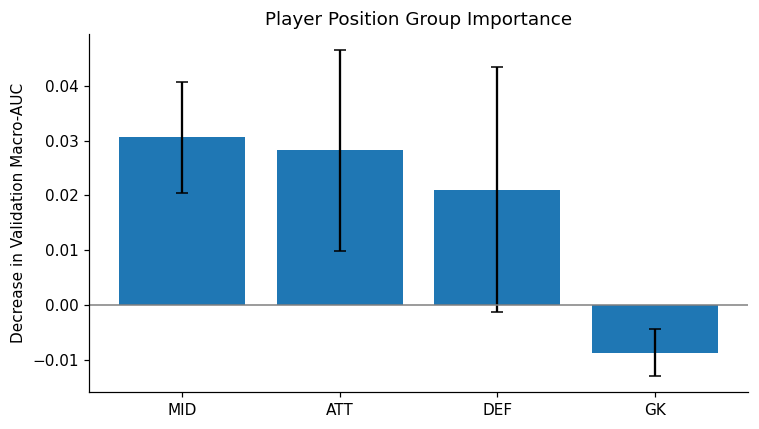

In [58]:
# grouped permutation importance for player positions
from sklearn.metrics import roc_auc_score

model, cols = fitted_models['Club + Individual']
X_valid = df.loc[valid_mask, cols].copy()
y = df.loc[valid_mask, 'label_90min_wdl']

def get_auc(X):
    p = model.predict_proba(X)
    return roc_auc_score(
        y, p, labels=model.classes_,
        multi_class='ovr', average='macro')
base_auc = get_auc(X_valid)

groups = {
    'GK': ['gk'],
    'DEF': ['def'],
    'MID': ['mid'],
    'ATT': ['att']
}
rng = np.random.default_rng(42)
importance_rows = []

for group, prefixes in groups.items():
    group_cols = [c for c in cols if any(c.startswith(f'{side}_{prefix}') for side in ['home', 'away'] for prefix in prefixes)]

    drops = []
    for _ in range(10):
        shuffled = X_valid.copy()
        idx = rng.permutation(len(shuffled))
        shuffled.loc[:, group_cols] = (X_valid[group_cols].iloc[idx].to_numpy())
        drops.append(base_auc - get_auc(shuffled))

    importance_rows.append({
        'position': group,
        'features': len(group_cols),
        'auc_drop': np.mean(drops),
        'std': np.std(drops)
    })

importance_df = pd.DataFrame(importance_rows).sort_values('auc_drop', ascending=False)
display(importance_df.round(4))

plt.figure(figsize=(7, 4))
plt.bar(
    importance_df['position'],
    importance_df['auc_drop'],
    yerr=importance_df['std'],
    capsize=4
)
plt.axhline(0, color='gray', linewidth=1)
plt.ylabel('Decrease in Validation Macro-AUC')
plt.title('Player Position Group Importance')
plt.tight_layout()
plt.show()

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.metrics import roc_auc_score

df = pd.read_csv('data/match_dataset/matches_full.csv')
train = df[df['season'] <= '2023-24'].copy()
valid = df[df['season'] == '2024-25'].copy()

SLOTS = {
    'GK': ['gk1'],
    'DEF': [f'def{i}' for i in range(1, 5)],
    'MID': [f'mid{i}' for i in range(1, 4)],
    'ATT': [f'att{i}' for i in range(1, 4)]
}

club_cols = [
    f'{side}_club_{attr}'
    for side in ['home', 'away']
    for attr in [
        'overall', 'attack', 'midfield', 'defence',
        'domestic_prestige', 'international_prestige'
    ]
] + ['neutral_venue', 'stage_league', 'stage_knockout']

# Get attributes available in both teams
all_attrs = sorted({c.split('home_gk1_', 1)[1] for c in df.columns if c.startswith('home_gk1_')})

# GK-specific ratings are not meaningful for outfield players
gk_attrs = [a for a in all_attrs if a.startswith('goalkeeping_')]
other_attrs = [a for a in all_attrs if not a.startswith('goalkeeping_')]

POSITION_ATTRS = {
    'GK': [
        a for a in all_attrs
        if a in gk_attrs or a in [
            'overall', 'potential', 'age', 'height_cm',
            'weight_kg', 'movement_reactions', 'power_jumping'
        ]
    ],
    'DEF': other_attrs,
    'MID': other_attrs,
    'ATT': other_attrs
}

# remove constant or purely categorical indicators from correlation analysis
for pos in POSITION_ATTRS:
    POSITION_ATTRS[pos] = [a for a in POSITION_ATTRS[pos] if a not in ['preferred_foot_left', 'role_mismatch']]

def position_attribute_mean(data, side, pos, attr):
    cols = [f'{side}_{slot}_{attr}' for slot in SLOTS[pos]]
    return data[cols].apply(pd.to_numeric, errors='coerce').mean(axis=1)

for pos, attrs in POSITION_ATTRS.items():
    print(f'{pos}: {len(attrs)} candidate attributes')


GK: 12 candidate attributes
DEF: 25 candidate attributes
MID: 25 candidate attributes
ATT: 25 candidate attributes


In [60]:
# position-specific partial correlation with goal difference
controls = train[club_cols].apply(pd.to_numeric, errors='coerce')
controls = controls.fillna(controls.median()).fillna(0)
y = train['label_90min_goal_diff'].astype(float)
corr_rows = []

for pos, attrs in POSITION_ATTRS.items():
    for attr in attrs:
        home = position_attribute_mean(train, 'home', pos, attr)
        away = position_attribute_mean(train, 'away', pos, attr)
        diff = home - away
        mask = diff.notna() & np.isfinite(diff) & y.notna()

        if mask.sum() < 100 or diff[mask].nunique() < 2:
            continue

        X_control = controls.loc[mask]
        x = diff[mask]
        target = y[mask]
        raw_corr = pearsonr(x, target)[0]

        # remove relationships explained by club ratings
        x_resid = x - LinearRegression().fit(X_control, x).predict(X_control)
        y_resid = target - LinearRegression().fit(X_control, target).predict(X_control)

        partial_corr = (
            pearsonr(x_resid, y_resid)[0]
            if x_resid.std() > 1e-10 and y_resid.std() > 1e-10 else np.nan
        )

        corr_rows.append({
            'position': pos,
            'attribute': attr,
            'n': mask.sum(),
            'raw_corr': raw_corr,
            'partial_corr': partial_corr
        })

position_corr = pd.DataFrame(corr_rows)
position_corr['abs_partial'] = position_corr['partial_corr'].abs()

for pos in SLOTS:
    print(f'\n{pos} — Top attributes')
    top = position_corr[position_corr['position'] == pos]
    display(top.sort_values('abs_partial', ascending=False).head(10).round(4))



GK — Top attributes


,position,attribute,n,raw_corr,partial_corr,abs_partial
3,GK,goalkeeping_kicking,1086,0.3042,0.1106,0.1106
0,GK,age,1086,-0.0774,-0.1051,0.1051
4,GK,goalkeeping_positioning,1086,0.3110,-0.0867,0.0867
5,GK,goalkeeping_reflexes,1086,0.3467,-0.0665,0.0665
8,GK,overall,1086,0.4049,-0.0646,0.0646
2,GK,goalkeeping_handling,1086,0.3544,-0.0452,0.0452
7,GK,movement_reactions,1086,0.3528,-0.0349,0.0349
6,GK,height_cm,1086,0.0230,-0.0307,0.0307
10,GK,power_jumping,1086,0.0852,-0.0210,0.0210
9,GK,potential,1086,0.4124,0.0139,0.0139



DEF — Top attributes


,position,attribute,n,raw_corr,partial_corr,abs_partial
14,DEF,attacking_short_passing,1086,0.4187,0.0979,0.0979
26,DEF,potential,1086,0.4980,0.0964,0.0964
33,DEF,skill_long_passing,1086,0.3698,0.0918,0.0918
12,DEF,age,1086,-0.0243,-0.0881,0.0881
18,DEF,mentality_composure,898,0.3700,-0.0817,0.0817
31,DEF,skill_ball_control,1086,0.3940,0.0740,0.0740
23,DEF,movement_reactions,1086,0.4809,0.0686,0.0686
35,DEF,weak_foot,1086,0.1571,0.0680,0.0680
20,DEF,mentality_vision,1086,0.2945,0.0533,0.0533
28,DEF,power_shot_power,1086,0.2749,0.0511,0.0511



MID — Top attributes


,position,attribute,n,raw_corr,partial_corr,abs_partial
51,MID,potential,1086,0.4733,0.0822,0.0822
53,MID,power_shot_power,1086,0.1953,-0.0689,0.0689
48,MID,movement_reactions,1086,0.4696,0.0624,0.0624
50,MID,overall,1086,0.4853,0.0503,0.0503
61,MID,weight_kg,1086,-0.0248,-0.0424,0.0424
58,MID,skill_long_passing,1086,0.3657,-0.0422,0.0422
55,MID,power_strength,1086,0.0351,-0.0385,0.0385
37,MID,age,1086,0.1126,-0.0350,0.0350
59,MID,skill_moves,1086,0.1973,0.0273,0.0273
47,MID,movement_agility,1086,0.1509,0.0252,0.0252



ATT — Top attributes


,position,attribute,n,raw_corr,partial_corr,abs_partial
83,ATT,skill_long_passing,1086,0.2268,-0.1046,0.1046
62,ATT,age,1086,0.0567,-0.0898,0.0898
69,ATT,mentality_interceptions,1086,0.0791,-0.0874,0.0874
68,ATT,mentality_composure,898,0.3309,-0.0793,0.0793
76,ATT,potential,1086,0.4608,0.0677,0.0677
65,ATT,defending_marking_awareness,1086,0.0622,-0.0642,0.0642
78,ATT,power_shot_power,1086,0.2994,-0.0463,0.0463
66,ATT,defending_standing_tackle,1086,0.0908,-0.0459,0.0459
70,ATT,mentality_vision,1086,0.3080,-0.0394,0.0394
64,ATT,attacking_short_passing,1086,0.3398,-0.0384,0.0384


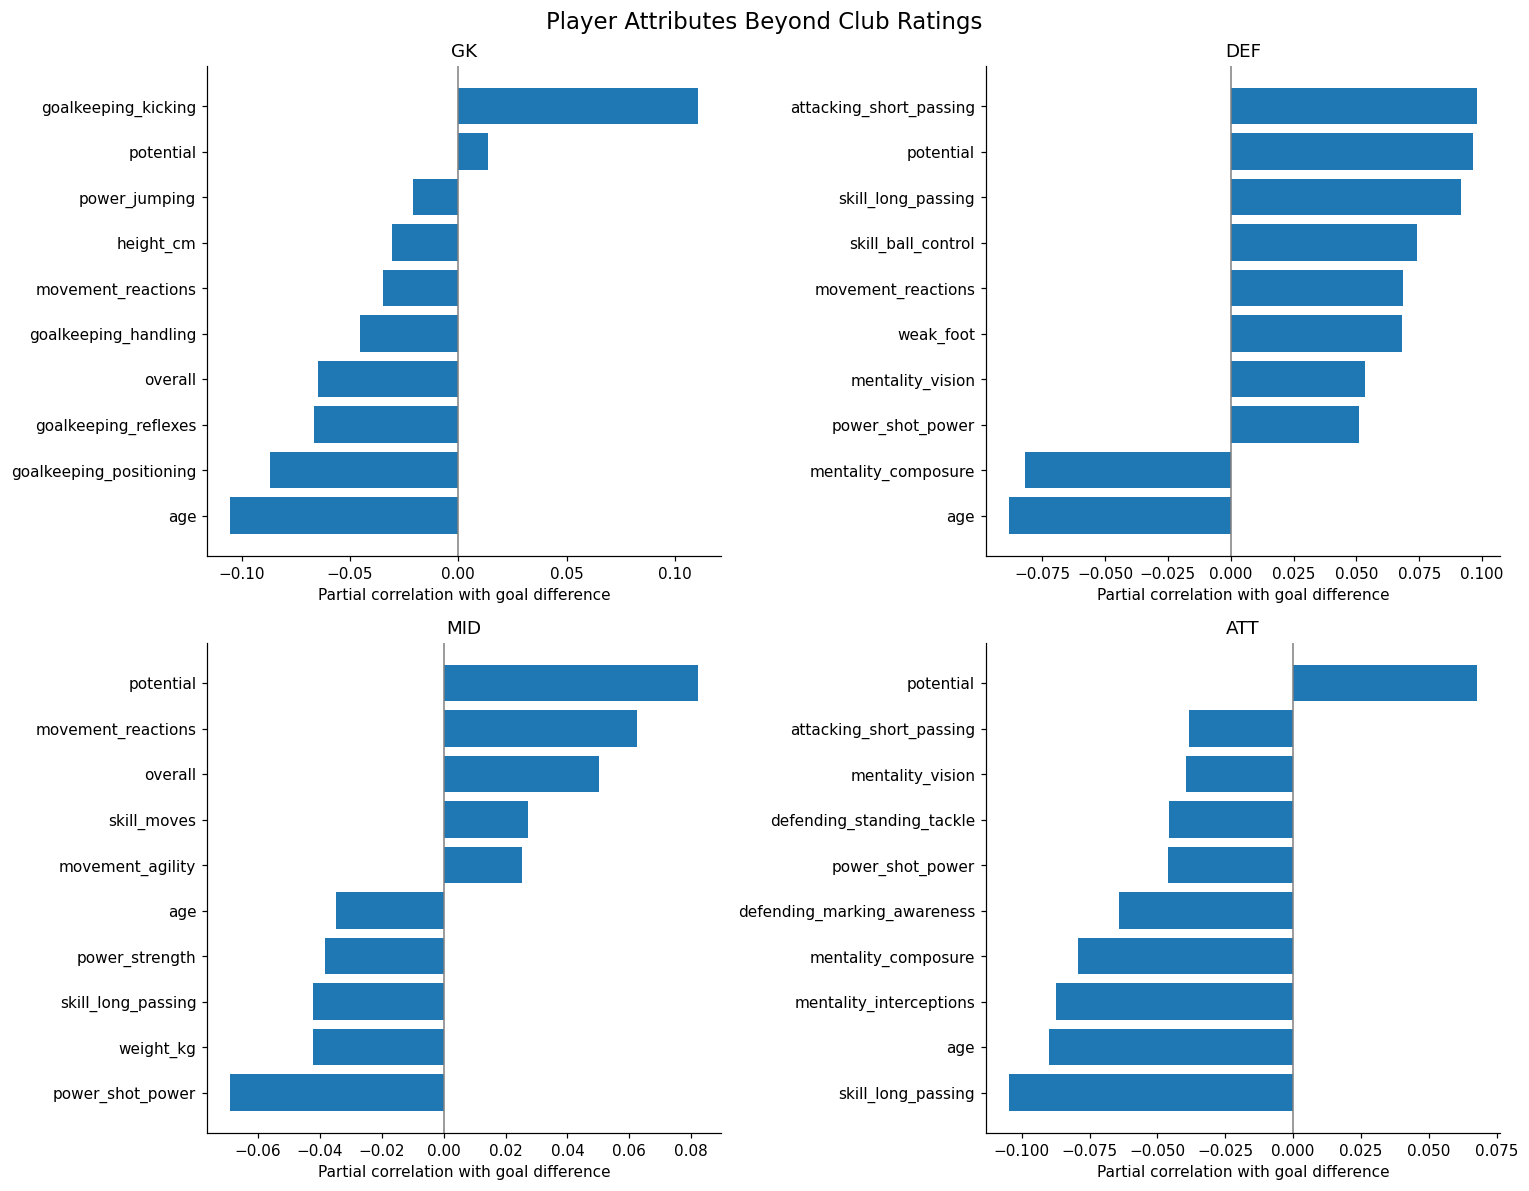

In [61]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, pos in zip(axes.flat, SLOTS):
    top = (position_corr[position_corr['position'] == pos].nlargest(10, 'abs_partial').sort_values('partial_corr'))
    ax.barh(top['attribute'], top['partial_corr'])
    ax.axvline(0, color='gray', linewidth=1)
    ax.set_title(pos)
    ax.set_xlabel('Partial correlation with goal difference')

plt.suptitle('Player Attributes Beyond Club Ratings', fontsize=15)
plt.tight_layout()
plt.show()

### Position-Specific Player Attribute Analysis

Examine individual player attributes within GK, DEF, MID, and ATT using partial correlation and permutation importance to identify useful features beyond club ratings.

| Position | Key Findings |
|---|---|
| GK | Kicking, positioning, and age showed relatively strong partial correlations, while positioning and physical attributes contributed to model predictions. |
| DEF | Interceptions and sprint speed showed the highest importance, while passing ability and potential also showed additional correlations with match outcomes. |
| MID | Reactions, short passing, and potential appeared promising, suggesting that both technical ability and player quality may be useful. |
| ATT | Reactions, height, age, and potential were relatively important, while several attributes showed additional correlations beyond club ratings. |

**Conclusion:** Each position contains potentially useful player attributes, but their importance varies by position and evaluation method. Rather than directly using hundreds of individual features, I will construct a smaller set of position-aware statistics and test whether they improve predictions beyond Club Only.

In [62]:
# Attribute importance within each position group
model, used_cols = fitted_models['Club + Individual']

X_valid = valid[used_cols].copy()
y_valid = valid['label_90min_wdl']

def multiclass_auc(X):
    probs = model.predict_proba(X)
    return roc_auc_score(
        y_valid, probs,
        labels=model.classes_,
        multi_class='ovr',
        average='macro'
    )

baseline_auc = multiclass_auc(X_valid)
rng = np.random.default_rng(42)
importance_rows = []

N_REPEATS = 10
for pos, attrs in POSITION_ATTRS.items():
    for attr in attrs:
        group_cols = [
            f'{side}_{slot}_{attr}'
            for side in ['home', 'away']
            for slot in SLOTS[pos]
            if f'{side}_{slot}_{attr}' in used_cols
        ]

        if not group_cols:
            continue

        auc_drops = []
        for _ in range(N_REPEATS):
            shuffled = X_valid.copy()
            idx = rng.permutation(len(X_valid))
            shuffled[group_cols] = (X_valid[group_cols].iloc[idx].to_numpy())
            auc_drops.append(baseline_auc - multiclass_auc(shuffled))

        importance_rows.append({
            'position': pos,
            'attribute': attr,
            'n_columns': len(group_cols),
            'auc_drop': np.mean(auc_drops),
            'std': np.std(auc_drops)
        })

attribute_importance = pd.DataFrame(importance_rows)

print(f'Original Validation Macro-AUC: {baseline_auc:.4f}')

for pos in SLOTS:
    print(f'\n{pos} — Top attributes')
    display(attribute_importance[attribute_importance['position'] == pos].sort_values('auc_drop', ascending=False).head(10).round(4))


Original Validation Macro-AUC: 0.5774

GK — Top attributes


,position,attribute,n_columns,auc_drop,std
11,GK,weight_kg,2,0.0048,0.0029
4,GK,goalkeeping_positioning,2,0.0025,0.0016
0,GK,age,2,0.0015,0.0029
9,GK,potential,2,0.0014,0.0010
2,GK,goalkeeping_handling,2,0.0004,0.0010
3,GK,goalkeeping_kicking,2,0.0003,0.0028
1,GK,goalkeeping_diving,2,0.0000,0.0019
6,GK,height_cm,2,-0.0002,0.0016
8,GK,overall,2,-0.0006,0.0006
10,GK,power_jumping,2,-0.0006,0.0011



DEF — Top attributes


,position,attribute,n_columns,auc_drop,std
19,DEF,mentality_interceptions,8,0.0158,0.0047
24,DEF,movement_sprint_speed,8,0.0108,0.0040
28,DEF,power_shot_power,8,0.0084,0.0062
25,DEF,overall,8,0.0073,0.0037
14,DEF,attacking_short_passing,8,0.0063,0.0047
30,DEF,power_strength,8,0.0057,0.0038
23,DEF,movement_reactions,8,0.0052,0.0050
33,DEF,skill_long_passing,8,0.0051,0.0047
16,DEF,defending_standing_tackle,8,0.0037,0.0027
32,DEF,skill_dribbling,8,0.0033,0.0027



MID — Top attributes


,position,attribute,n_columns,auc_drop,std
48,MID,movement_reactions,6,0.0075,0.0035
39,MID,attacking_short_passing,6,0.0072,0.0033
61,MID,weight_kg,6,0.0070,0.0039
43,MID,mentality_composure,6,0.0070,0.0046
49,MID,movement_sprint_speed,6,0.0057,0.0029
42,MID,height_cm,6,0.0043,0.0028
51,MID,potential,6,0.0041,0.0041
45,MID,mentality_vision,6,0.0038,0.0023
37,MID,age,6,0.0034,0.0033
41,MID,defending_standing_tackle,6,0.0029,0.0032



ATT — Top attributes


,position,attribute,n_columns,auc_drop,std
73,ATT,movement_reactions,6,0.0157,0.0043
67,ATT,height_cm,6,0.0125,0.0054
62,ATT,age,6,0.0095,0.0038
76,ATT,potential,6,0.0084,0.0033
75,ATT,overall,6,0.0079,0.0022
70,ATT,mentality_vision,6,0.0070,0.0023
85,ATT,weak_foot,6,0.0053,0.0035
84,ATT,skill_moves,6,0.0036,0.0032
66,ATT,defending_standing_tackle,6,0.0030,0.0034
81,ATT,skill_ball_control,6,0.0027,0.0057


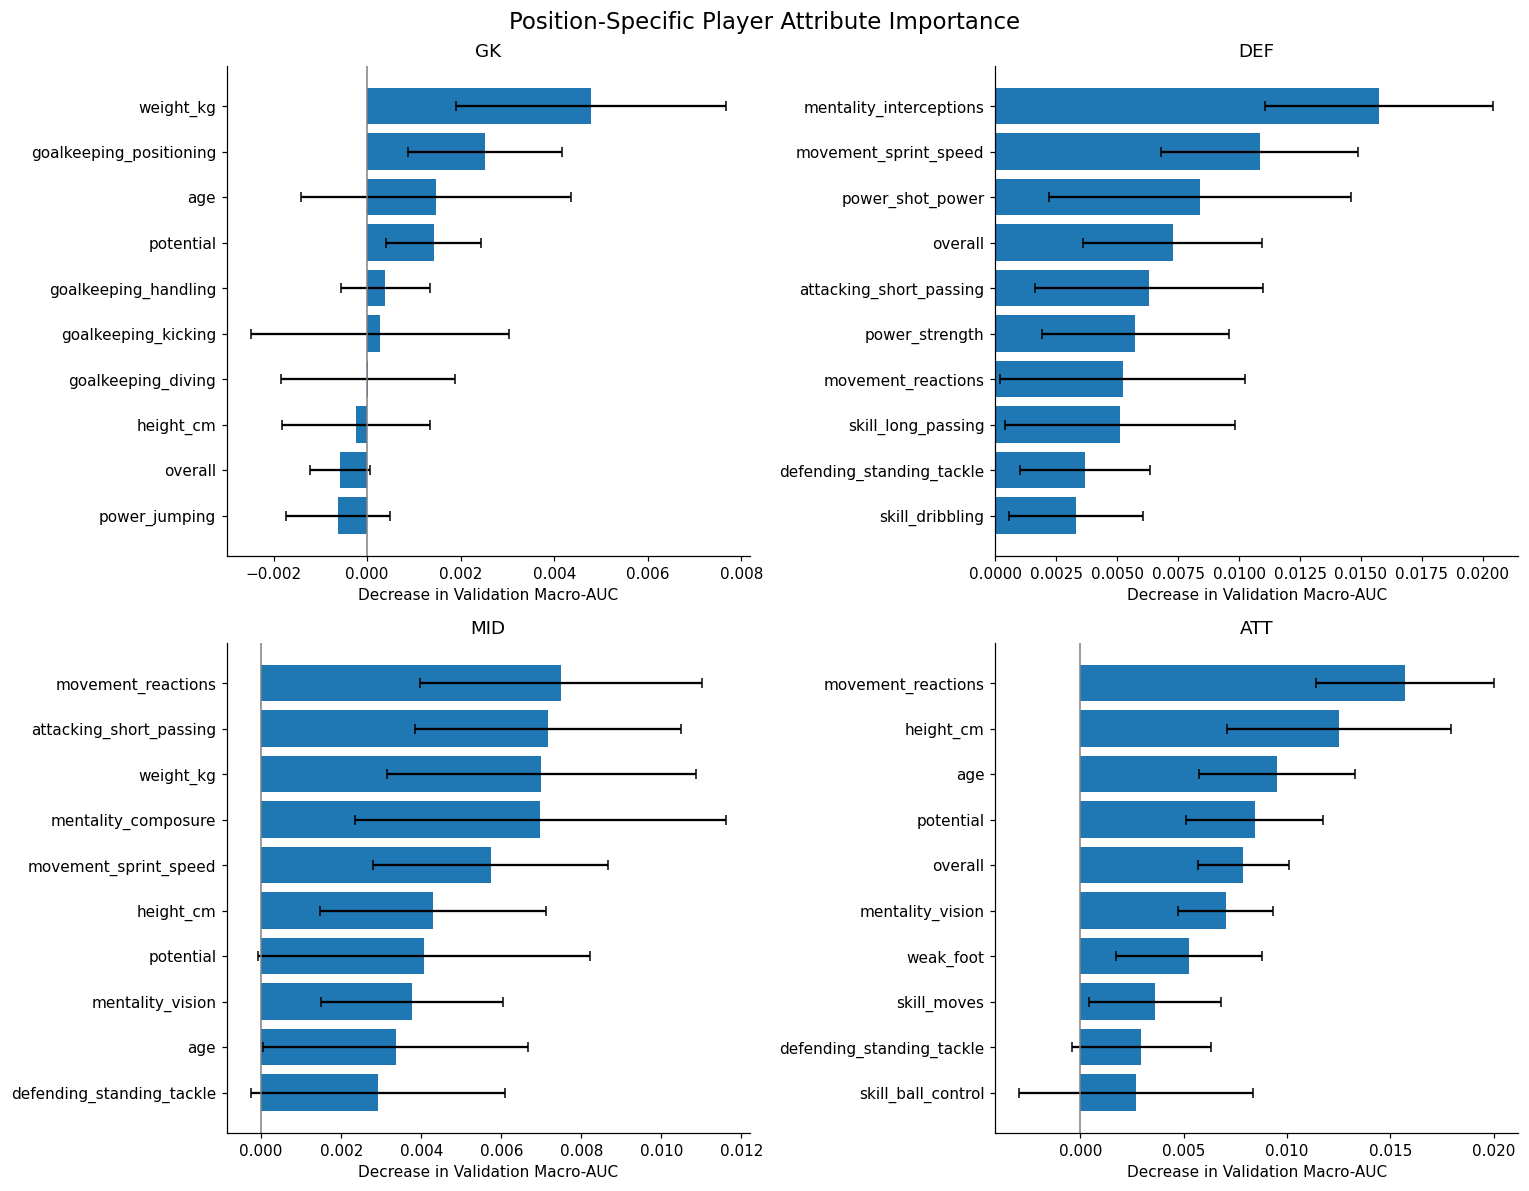

In [63]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, pos in zip(axes.flat, SLOTS):
    top = (attribute_importance[attribute_importance['position'] == pos].nlargest(10, 'auc_drop').sort_values('auc_drop'))

    ax.barh(top['attribute'], top['auc_drop'], xerr=top['std'], capsize=3)
    ax.axvline(0, color='gray', linewidth=1)
    ax.set_title(pos)
    ax.set_xlabel('Decrease in Validation Macro-AUC')

plt.suptitle('Position-Specific Player Attribute Importance', fontsize=15)
plt.tight_layout()
plt.show()


from pathlib import Path
out_dir = Path('model/results/position_analysis')
out_dir.mkdir(parents=True, exist_ok=True)

position_corr.to_csv(out_dir / 'position_partial_correlations.csv', index=False)
attribute_importance.to_csv(out_dir / 'position_attribute_importance.csv', index=False)

# Part IX Position-Aware Feature Engineering & Incremental Tests

### XGBoost Player Feature Importance

Analyze XGBoost feature importance across nine feature sets and three prediction approaches to identify useful player attributes.

| Position | Key Findings |
|---|---|
| GK | Kicking, potential, age, and overall ratings appeared relatively frequently among important features. |
| DEF | Overall, potential, reactions, interceptions, tackling, and short passing showed consistent importance across experiments. |
| MID | Overall, reactions, potential, and short passing were the most consistently important attributes. |
| ATT | Reactions, finishing, potential, and overall ratings stood out, with some evidence supporting maximum individual ability. |

**Conclusion:** Several player attributes were consistently used by XGBoost, especially defensive ability, midfield reactions, and attacking finishing. However, the larger feature sets did not consistently improve validation performance. I will therefore test a smaller, position-aware feature set to reduce redundancy and evaluate whether player-level information adds predictive value beyond club ratings.

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, log_loss

df = pd.read_csv('data/match_dataset/matches_full.csv')

train_idx = df.index[df['season'] <= '2023-24']
valid_idx = df.index[df['season'] == '2024-25']

CLUB = [
    f'{side}_club_{attr}'
    for side in ['home', 'away']
    for attr in [
        'overall', 'attack', 'midfield', 'defence',
        'domestic_prestige', 'international_prestige'
    ]
] + ['neutral_venue', 'stage_league', 'stage_knockout']

SLOTS = {
    'GK': ['gk1'],
    'DEF': [f'def{i}' for i in range(1, 5)],
    'MID': [f'mid{i}' for i in range(1, 4)],
    'ATT': [f'att{i}' for i in range(1, 4)]
}

print('Train:', len(train_idx), 'Validation:', len(valid_idx))

Train: 1086 Validation: 173


In [65]:
# Candidate attributes for each position
ATTR = {
    'GK': [
        'goalkeeping_kicking', 'age', 'goalkeeping_positioning',
        'goalkeeping_reflexes', 'overall', 'goalkeeping_handling',
        'weight_kg', 'potential', 'goalkeeping_diving'
    ],
    'DEF': [
        'attacking_short_passing', 'potential', 'skill_long_passing',
        'age', 'mentality_composure', 'skill_ball_control',
        'movement_reactions', 'weak_foot', 'mentality_vision',
        'power_shot_power', 'mentality_interceptions',
        'movement_sprint_speed', 'overall', 'power_strength',
        'defending_standing_tackle', 'skill_dribbling'
    ],
    'MID': [
        'potential', 'power_shot_power', 'movement_reactions',
        'overall', 'weight_kg', 'skill_long_passing',
        'power_strength', 'age', 'skill_moves', 'movement_agility',
        'attacking_short_passing', 'mentality_composure',
        'movement_sprint_speed', 'height_cm', 'mentality_vision',
        'defending_standing_tackle', 'skill_ball_control',
        'power_stamina'
    ],
    'ATT': [
        'skill_long_passing', 'age', 'mentality_interceptions',
        'mentality_composure', 'potential',
        'defending_marking_awareness', 'power_shot_power',
        'defending_standing_tackle', 'mentality_vision',
        'attacking_short_passing', 'movement_reactions',
        'height_cm', 'overall', 'weak_foot', 'skill_moves',
        'skill_ball_control', 'attacking_finishing',
        'movement_acceleration', 'skill_dribbling'
    ]
}

# Additional statistics for selected attributes
EXTRA = {
    'DEF': ['mentality_interceptions', 'movement_sprint_speed', 'attacking_short_passing', 'defending_standing_tackle'],
    'MID': ['movement_reactions', 'attacking_short_passing', 'potential'],
    'ATT': ['movement_reactions', 'attacking_finishing', 'height_cm']
}
print({pos: len(attrs) for pos, attrs in ATTR.items()})

{'GK': 9, 'DEF': 16, 'MID': 18, 'ATT': 19}


In [67]:
def build_position_features(data):
    result = {}
    groups = {pos: [] for pos in SLOTS}

    for side in ['home', 'away']:
        for pos, slots in SLOTS.items():
            for attr in ATTR[pos]:
                cols = [f'{side}_{slot}_{attr}' for slot in slots]
                values = data[cols].apply(pd.to_numeric, errors='coerce')
                prefix = f'{side}_{pos.lower()}_{attr}'

                # Mean (GK has only one player)
                name = f'{prefix}_mean'
                result[name] = values.mean(axis=1)
                groups[pos].append(name)

                # Extra statistics for selected skills
                if attr in EXTRA.get(pos, []):
                    stats = {
                        'min': values.min(axis=1),
                        'max': values.max(axis=1),
                        'std': values.std(axis=1, ddof=0)
                    }

                    for stat, series in stats.items():
                        name = f'{prefix}_{stat}'
                        result[name] = series
                        groups[pos].append(name)

    return pd.DataFrame(result, index=data.index), groups


position_features, position_groups = build_position_features(df)
mean_cols = [
    c for c in position_features.columns
    if c.endswith('_mean')
]

print('Mean features:', len(mean_cols))
print('All position features:', position_features.shape[1])
print('Features by position:')
print({k: len(v) for k, v in position_groups.items()})

Mean features: 124
All position features: 184
Features by position:
{'GK': 18, 'DEF': 56, 'MID': 54, 'ATT': 56}


In [68]:
def build_diff(data, columns):
    result = pd.DataFrame(index=data.index)
    for h in columns:
        if not h.startswith('home_'):
            continue
        a = 'away_' + h[5:]
        if a in columns:
            result['diff_' + h[5:]] = data[h] - data[a]

    return result


position_diff = build_diff(position_features, mean_cols)
level_features = pd.DataFrame(index=df.index)

for h in mean_cols:
    if not h.startswith('home_'):
        continue

    if any(h.endswith(f'_{attr}_mean') for attr in ['overall', 'potential', 'age']):
        a = 'away_' + h[5:]
        level_features['level_' + h[5:]] = (position_features[h] + position_features[a]) / 2


context = df[['neutral_venue', 'stage_league', 'stage_knockout']]
feature_sets = {
    'Club Only':
        df[CLUB],

    'Club + GK':
        pd.concat([df[CLUB],
                   position_features[position_groups['GK']]], axis=1),

    'Club + DEF':
        pd.concat([df[CLUB],
                   position_features[position_groups['DEF']]], axis=1),

    'Club + MID':
        pd.concat([df[CLUB],
                   position_features[position_groups['MID']]], axis=1),

    'Club + ATT':
        pd.concat([df[CLUB],
                   position_features[position_groups['ATT']]], axis=1),

    'Club + All Means':
        pd.concat([df[CLUB],
                   position_features[mean_cols]], axis=1),

    'Club + Mean/Min/Max/Std':
        pd.concat([df[CLUB], position_features], axis=1),

    'Position Diff Only':
        pd.concat([context, position_diff], axis=1),

    'Club + Position Diff':
        pd.concat([df[CLUB], position_diff], axis=1),

    'Club + Position Diff + Level':
        pd.concat([df[CLUB], position_diff,
                   level_features], axis=1)
}

for name, X in feature_sets.items():
    assert X.columns.is_unique
    print(f'{name:35s}: {X.shape[1]} features')

Club Only                          : 15 features
Club + GK                          : 33 features
Club + DEF                         : 71 features
Club + MID                         : 69 features
Club + ATT                         : 71 features
Club + All Means                   : 139 features
Club + Mean/Min/Max/Std            : 199 features
Position Diff Only                 : 65 features
Club + Position Diff               : 77 features
Club + Position Diff + Level       : 89 features


In [69]:
y = df['label_90min_wdl']

results = []
trained_models = {}

for name, X in feature_sets.items():
    X = X.apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)

    # Remove constant features using training data only
    keep = [
        c for c in X.columns
        if X.loc[train_idx, c].notna().any()
        and X.loc[train_idx, c].nunique(dropna=True) > 1
    ]

    X_train = X.loc[train_idx, keep]
    X_valid = X.loc[valid_idx, keep]

    model = make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler(),
        LogisticRegression(C=0.1, max_iter=3000, random_state=42)
    )

    model.fit(X_train, y.loc[train_idx])
    pred = model.predict(X_valid)
    prob = model.predict_proba(X_valid)

    results.append({
        'feature_set': name,
        'n_features': len(keep),
        'accuracy': accuracy_score(y.loc[valid_idx], pred),
        'macro_f1': f1_score(
            y.loc[valid_idx], pred, average='macro'
        ),
        'macro_auc': roc_auc_score(
            y.loc[valid_idx], prob,
            labels=model.classes_,
            multi_class='ovr',
            average='macro'
        ),
        'log_loss': log_loss(
            y.loc[valid_idx], prob,
            labels=model.classes_
        )
    })

    trained_models[name] = (model, keep)

results_df = pd.DataFrame(results)

baseline = results_df.loc[results_df['feature_set'] == 'Club Only'].iloc[0]
results_df['auc_gain'] = (results_df['macro_auc'] - baseline['macro_auc'])
results_df['accuracy_gain'] = (results_df['accuracy'] - baseline['accuracy'])
results_df = results_df.sort_values('macro_auc', ascending=False)
display(results_df.round(4))

,feature_set,n_features,accuracy,macro_f1,macro_auc,log_loss,auc_gain,accuracy_gain
0,Club Only,15,0.5665,0.4071,0.6701,0.9287,0.0000,0.0000
2,Club + DEF,71,0.5376,0.4475,0.6693,0.9661,-0.0008,-0.0289
1,Club + GK,33,0.5549,0.3977,0.6625,0.9545,-0.0076,-0.0116
6,Club + Mean/Min/Max/Std,199,0.5318,0.4547,0.6573,1.0539,-0.0128,-0.0347
8,Club + Position Diff,77,0.5491,0.3982,0.6509,0.9946,-0.0192,-0.0173
5,Club + All Means,139,0.5202,0.4140,0.6473,1.0531,-0.0228,-0.0462
9,Club + Position Diff + Level,89,0.5434,0.4119,0.6468,1.0063,-0.0233,-0.0231
4,Club + ATT,71,0.5549,0.3931,0.6463,0.9666,-0.0238,-0.0116
3,Club + MID,69,0.5665,0.3992,0.6437,0.9331,-0.0263,0.0000
7,Position Diff Only,65,0.5376,0.4045,0.6321,1.0064,-0.0379,-0.0289


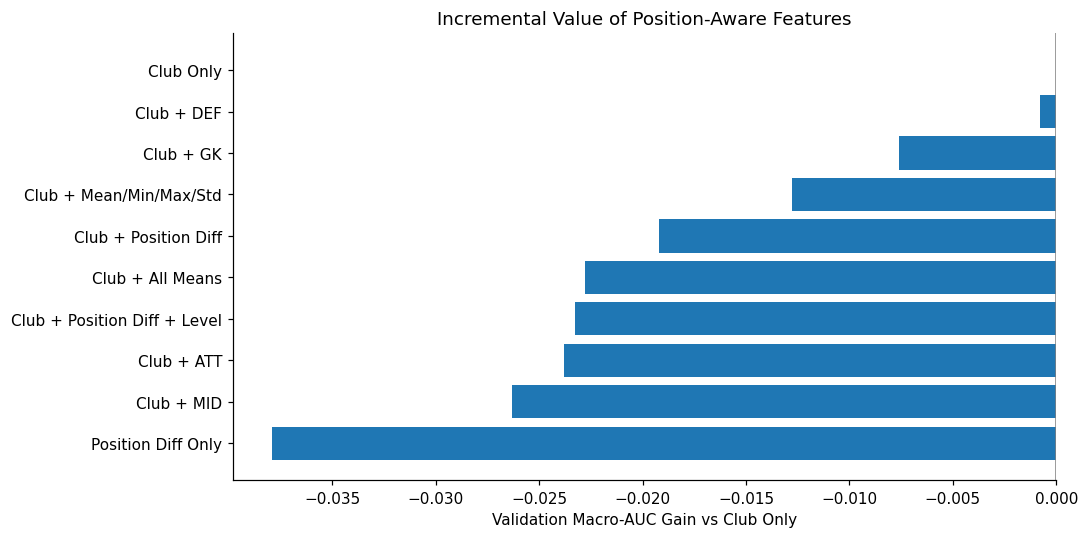

Saved to: model\results\position_aware


In [70]:
plot_df = results_df.sort_values('auc_gain')

plt.figure(figsize=(10, 5))
plt.barh(plot_df['feature_set'], plot_df['auc_gain'])
plt.axvline(0, color='gray', linewidth=1)

plt.xlabel('Validation Macro-AUC Gain vs Club Only')
plt.title('Incremental Value of Position-Aware Features')
plt.tight_layout()
plt.show()

# Save results
out_dir = Path('model/results/position_aware')
out_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(out_dir / 'position_incremental_validation.csv', index=False)

# Save new features without changing the original dataset
export_df = pd.concat([df[['match_id', 'season', 'label_90min_wdl']], position_features], axis=1)
export_df.to_csv(out_dir / 'position_features_all_matches.csv', index=False)
print('Saved to:', out_dir)

# Part X Nonlinear Models and Feature Importance

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, PoissonRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, log_loss
from scipy.stats import norm, poisson
from xgboost import XGBClassifier, XGBRegressor
from catboost import CatBoostClassifier, CatBoostRegressor
from IPython.display import display
from pathlib import Path
from sklearn.base import clone

OUT = Path('model/results/position_nonlinear')
OUT.mkdir(parents=True, exist_ok=True)

# Start with these groups; add more from feature_sets if needed
GROUPS = [
    'Club Only',
    'Club + GK',
    'Club + DEF',
    'Club + MID',
    'Club + ATT',
    'Club + All Means',
    'Club + Mean/Min/Max/Std',
    'Club + Position Diff',
    'Club + Position Diff + Level'
]

LABELS = ['A', 'D', 'H']
y_wdl = df['label_90min_wdl'].map({'A': 0, 'D': 1, 'H': 2})

# For regression tasks
y_diff = df['label_90min_goal_diff'].astype(float)
y_home = df['label_90min_home_goals'].astype(float)
y_away = df['label_90min_away_goals'].astype(float)

def build_model(task, algo):
    if task == 'wdl':
        models = {
            'Logistic': LogisticRegression(C=0.1, max_iter=3000),
            'RandomForest': RandomForestClassifier(
                n_estimators=200, max_depth=5,
                min_samples_leaf=8, n_jobs=-1, random_state=42
            ),
            'XGBoost': XGBClassifier(
                n_estimators=200, max_depth=3,
                learning_rate=0.04, subsample=0.8,
                colsample_bytree=0.8, reg_lambda=10,
                objective='multi:softprob', num_class=3,
                n_jobs=-1, random_state=42
            ),
            'CatBoost': CatBoostClassifier(
                iterations=300, depth=4,
                learning_rate=0.04, l2_leaf_reg=10,
                loss_function='MultiClass',
                verbose=False, random_seed=42,
                thread_count=4
            )
        }
    else:
        models = {
            'Linear': LinearRegression(),
            'Poisson': PoissonRegressor(alpha=1.0, max_iter=1000),
            'RandomForest': RandomForestRegressor(
                n_estimators=200, max_depth=5,
                min_samples_leaf=8, n_jobs=-1, random_state=42
            ),
            'XGBoost': XGBRegressor(
                n_estimators=200, max_depth=3,
                learning_rate=0.04, subsample=0.8,
                colsample_bytree=0.8, reg_lambda=10,
                objective='reg:squarederror',
                n_jobs=-1, random_state=42
            ),
            'CatBoost': CatBoostRegressor(
                iterations=300, depth=4,
                learning_rate=0.04, l2_leaf_reg=10,
                loss_function='RMSE',
                verbose=False, random_seed=42,
                thread_count=4
            )
        }

    model = models[algo]
    scaler = [StandardScaler()] if algo in ['Logistic', 'Linear', 'Poisson'] else []

    return make_pipeline(SimpleImputer(strategy='median'), *scaler, model)

def get_probs_from_diff(mu, sigma):
    sigma = max(float(sigma), 0.5)
    p_a = norm.cdf(-0.5, loc=mu, scale=sigma)
    p_h = 1 - norm.cdf(0.5, loc=mu, scale=sigma)
    return np.column_stack([p_a, 1 - p_a - p_h, p_h])

def get_probs_from_goals(home_mu, away_mu, draw_weight=0.75):
    home_mu = np.maximum(np.asarray(home_mu), 0.01)
    away_mu = np.maximum(np.asarray(away_mu), 0.01)

    goals = np.arange(16)
    ph = poisson.pmf(goals[None, :], home_mu[:, None])
    pa = poisson.pmf(goals[None, :], away_mu[:, None])

    ph /= ph.sum(axis=1, keepdims=True)
    pa /= pa.sum(axis=1, keepdims=True)

    p_d = (ph * pa).sum(axis=1)
    p_h = (ph * np.cumsum(pa, axis=1, dtype=float)
           - ph * pa).sum(axis=1)
    p_a = 1 - p_h - p_d

    probs = np.column_stack([p_a, p_d * draw_weight, p_h])
    return probs / probs.sum(axis=1, keepdims=True)

def evaluate_wdl(y, probs):
    probs = np.clip(np.asarray(probs), 1e-10, 1)
    probs /= probs.sum(axis=1, keepdims=True)
    pred = probs.argmax(axis=1)

    return {
        'accuracy': accuracy_score(y, pred),
        'macro_f1': f1_score(y, pred, average='macro',
                             labels=[0, 1, 2], zero_division=0),
        'macro_auc': roc_auc_score(
            y, probs, multi_class='ovr',
            average='macro', labels=[0, 1, 2]
        ),
        'log_loss': log_loss(y, probs, labels=[0, 1, 2])
    }

def prepare_group(name):
    X = feature_sets[name].apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)
    keep = [c for c in X.columns if X.loc[train_idx, c].notna().any() and X.loc[train_idx, c].nunique(dropna=True) > 1]
    return X.loc[train_idx, keep], X.loc[valid_idx, keep], keep

print('Ready:', len(GROUPS), 'feature groups')

Ready: 9 feature groups


In [72]:
results = []
model_bank = {}

for group in GROUPS:
    Xtr, Xva, cols = prepare_group(group)
    yt = y_wdl.loc[train_idx].to_numpy()
    yv = y_wdl.loc[valid_idx].to_numpy()

    print(f'Training: {group} ({len(cols)} features)')

    # Route 1: Direct WDL
    for algo in ['Logistic', 'RandomForest', 'XGBoost', 'CatBoost']:
        model = build_model('wdl', algo)
        model.fit(Xtr, yt)

        probs = model.predict_proba(Xva)
        result = evaluate_wdl(yv, probs)

        key = ('Direct WDL', group, algo)
        model_bank[key] = {'models': [model], 'columns': cols}

        results.append({
            'route': key[0], 'feature_set': group,
            'model': algo, 'n_features': len(cols), **result
        })

    # Route 2: Goal Difference
    for algo in ['Linear', 'RandomForest', 'XGBoost', 'CatBoost']:
        model = build_model('reg', algo)
        model.fit(Xtr, y_diff.loc[train_idx])

        sigma = np.std(
            y_diff.loc[train_idx] - model.predict(Xtr)
        )
        probs = get_probs_from_diff(model.predict(Xva), sigma)
        result = evaluate_wdl(yv, probs)

        key = ('Goal Difference', group, algo)
        model_bank[key] = {
            'models': [model], 'columns': cols, 'sigma': sigma
        }

        results.append({
            'route': key[0], 'feature_set': group,
            'model': algo, 'n_features': len(cols), **result
        })

    # Route 3: Two Goals
    for algo in ['Poisson', 'RandomForest', 'XGBoost', 'CatBoost']:
        home_model = build_model('reg', algo)
        away_model = build_model('reg', algo)

        home_model.fit(Xtr, y_home.loc[train_idx])
        away_model.fit(Xtr, y_away.loc[train_idx])

        probs = get_probs_from_goals(
            home_model.predict(Xva),
            away_model.predict(Xva)
        )
        result = evaluate_wdl(yv, probs)

        key = ('Two Goals', group, algo)
        model_bank[key] = {
            'models': [home_model, away_model],
            'columns': cols
        }

        results.append({
            'route': key[0], 'feature_set': group,
            'model': algo, 'n_features': len(cols), **result
        })

results_nonlinear = pd.DataFrame(results)

results_nonlinear.to_csv(OUT / 'nonlinear_validation_all.csv', index=False)

# Best by route, ranked by Macro-AUC
best_by_route = (results_nonlinear.sort_values(['macro_auc', 'accuracy'], ascending=False).drop_duplicates('route'))
display(best_by_route.round(4))
display(results_nonlinear.sort_values('macro_auc', ascending=False).head(15).round(4))

Training: Club Only (15 features)
Training: Club + GK (33 features)
Training: Club + DEF (71 features)
Training: Club + MID (69 features)
Training: Club + ATT (71 features)
Training: Club + All Means (139 features)
Training: Club + Mean/Min/Max/Std (199 features)
Training: Club + Position Diff (77 features)
Training: Club + Position Diff + Level (89 features)


,route,feature_set,model,n_features,accuracy,macro_f1,macro_auc,log_loss
0,Direct WDL,Club Only,Logistic,15,0.5665,0.4071,0.6701,0.9287
4,Goal Difference,Club Only,Linear,15,0.5723,0.4085,0.6671,0.9161
33,Two Goals,Club + DEF,RandomForest,71,0.5491,0.3933,0.6640,0.9294


,route,feature_set,model,n_features,accuracy,macro_f1,macro_auc,log_loss
0,Direct WDL,Club Only,Logistic,15,0.5665,0.4071,0.6701,0.9287
24,Direct WDL,Club + DEF,Logistic,71,0.5376,0.4475,0.6693,0.9661
4,Goal Difference,Club Only,Linear,15,0.5723,0.4085,0.6671,0.9161
33,Two Goals,Club + DEF,RandomForest,71,0.5491,0.3933,0.6640,0.9294
55,Goal Difference,Club + ATT,CatBoost,71,0.5665,0.4046,0.6632,0.9468
12,Direct WDL,Club + GK,Logistic,33,0.5549,0.3977,0.6625,0.9545
8,Two Goals,Club Only,Poisson,15,0.5607,0.3986,0.6618,0.9175
47,Two Goals,Club + MID,CatBoost,69,0.5607,0.3986,0.6590,0.9303
72,Direct WDL,Club + Mean/Min/Max/Std,Logistic,199,0.5318,0.4547,0.6573,1.0539
30,Goal Difference,Club + DEF,XGBoost,71,0.5318,0.3805,0.6562,0.9756


In [73]:
# reuse best fitted models
rng = np.random.default_rng(42)
importance_rows = []

def predict_route(key, X):
    route, group, algo = key
    pack = model_bank[key]
    models = pack['models']

    if route == 'Direct WDL':
        return models[0].predict_proba(X)

    if route == 'Goal Difference':
        return get_probs_from_diff(models[0].predict(X),pack['sigma'])

    return get_probs_from_goals(models[0].predict(X), models[1].predict(X))

# Analyze the best model in each route
for _, winner in best_by_route.iterrows():
    key = (
        winner['route'],
        winner['feature_set'],
        winner['model']
    )

    _, Xvalid, cols = prepare_group(winner['feature_set'])
    yvalid = y_wdl.loc[valid_idx].to_numpy()

    base_auc = evaluate_wdl(
        yvalid, predict_route(key, Xvalid)
    )['macro_auc']

    print('Analyzing:', key)

    for col in cols:
        drops = []

        for repeat in range(5):
            shuffled = Xvalid.copy()
            shuffled[col] = rng.permutation(
                shuffled[col].to_numpy()
            )

            new_auc = evaluate_wdl(
                yvalid, predict_route(key, shuffled)
            )['macro_auc']

            drops.append(base_auc - new_auc)

        importance_rows.append({
            'route': key[0],
            'feature_set': key[1],
            'model': key[2],
            'feature': col,
            'auc_drop': np.mean(drops),
            'std': np.std(drops)
        })

importance_all = pd.DataFrame(importance_rows)

importance_all.to_csv(
    OUT / 'complete_permutation_importance.csv',
    index=False
)

for route in best_by_route['route']:
    print('\n', route)
    display(importance_all[importance_all['route'] == route].sort_values('auc_drop', ascending=False).head(20).round(4))


Analyzing: ('Direct WDL', 'Club Only', 'Logistic')
Analyzing: ('Goal Difference', 'Club Only', 'Linear')
Analyzing: ('Two Goals', 'Club + DEF', 'RandomForest')

 Direct WDL


,route,feature_set,model,feature,auc_drop,std
8,Direct WDL,Club Only,Logistic,away_club_midfield,0.0303,0.0072
1,Direct WDL,Club Only,Logistic,home_club_attack,0.0250,0.0087
6,Direct WDL,Club Only,Logistic,away_club_overall,0.0203,0.0118
0,Direct WDL,Club Only,Logistic,home_club_overall,0.0180,0.0123
10,Direct WDL,Club Only,Logistic,away_club_domestic_prestige,0.0166,0.0094
7,Direct WDL,Club Only,Logistic,away_club_attack,0.0133,0.0107
5,Direct WDL,Club Only,Logistic,home_club_international_prestige,0.0110,0.0067
11,Direct WDL,Club Only,Logistic,away_club_international_prestige,0.0093,0.0050
9,Direct WDL,Club Only,Logistic,away_club_defence,0.0038,0.0194
4,Direct WDL,Club Only,Logistic,home_club_domestic_prestige,0.0034,0.0052



 Goal Difference


,route,feature_set,model,feature,auc_drop,std
24,Goal Difference,Club Only,Linear,away_club_defence,0.0395,0.0153
15,Goal Difference,Club Only,Linear,home_club_overall,0.0242,0.0035
16,Goal Difference,Club Only,Linear,home_club_attack,0.0241,0.0175
22,Goal Difference,Club Only,Linear,away_club_attack,0.0160,0.0089
23,Goal Difference,Club Only,Linear,away_club_midfield,0.0144,0.0079
17,Goal Difference,Club Only,Linear,home_club_midfield,0.0089,0.0040
19,Goal Difference,Club Only,Linear,home_club_domestic_prestige,0.0051,0.0100
21,Goal Difference,Club Only,Linear,away_club_overall,0.0046,0.0066
26,Goal Difference,Club Only,Linear,away_club_international_prestige,0.0045,0.0058
25,Goal Difference,Club Only,Linear,away_club_domestic_prestige,0.0032,0.0013



 Two Goals


,route,feature_set,model,feature,auc_drop,std
32,Two Goals,Club + DEF,RandomForest,home_club_midfield,0.0242,0.0044
37,Two Goals,Club + DEF,RandomForest,away_club_attack,0.0073,0.0035
78,Two Goals,Club + DEF,RandomForest,away_def_skill_long_passing_mean,0.0034,0.0008
82,Two Goals,Club + DEF,RandomForest,away_def_movement_reactions_mean,0.0034,0.0036
73,Two Goals,Club + DEF,RandomForest,away_def_attacking_short_passing_mean,0.0033,0.0022
81,Two Goals,Club + DEF,RandomForest,away_def_skill_ball_control_mean,0.0029,0.0011
47,Two Goals,Club + DEF,RandomForest,home_def_attacking_short_passing_max,0.0025,0.0029
31,Two Goals,Club + DEF,RandomForest,home_club_attack,0.0021,0.0065
56,Two Goals,Club + DEF,RandomForest,home_def_mentality_vision_mean,0.0019,0.0010
75,Two Goals,Club + DEF,RandomForest,away_def_attacking_short_passing_max,0.0018,0.0008


,route,feature_set,model,group,n_features,auc_drop,std
0,Direct WDL,Club Only,Logistic,Club / Context,15,0.1771,0.0436
1,Goal Difference,Club Only,Linear,Club / Context,15,0.1604,0.0203
3,Two Goals,Club + DEF,RandomForest,DEF,56,0.0931,0.0341
2,Two Goals,Club + DEF,RandomForest,Club / Context,15,0.0210,0.0186


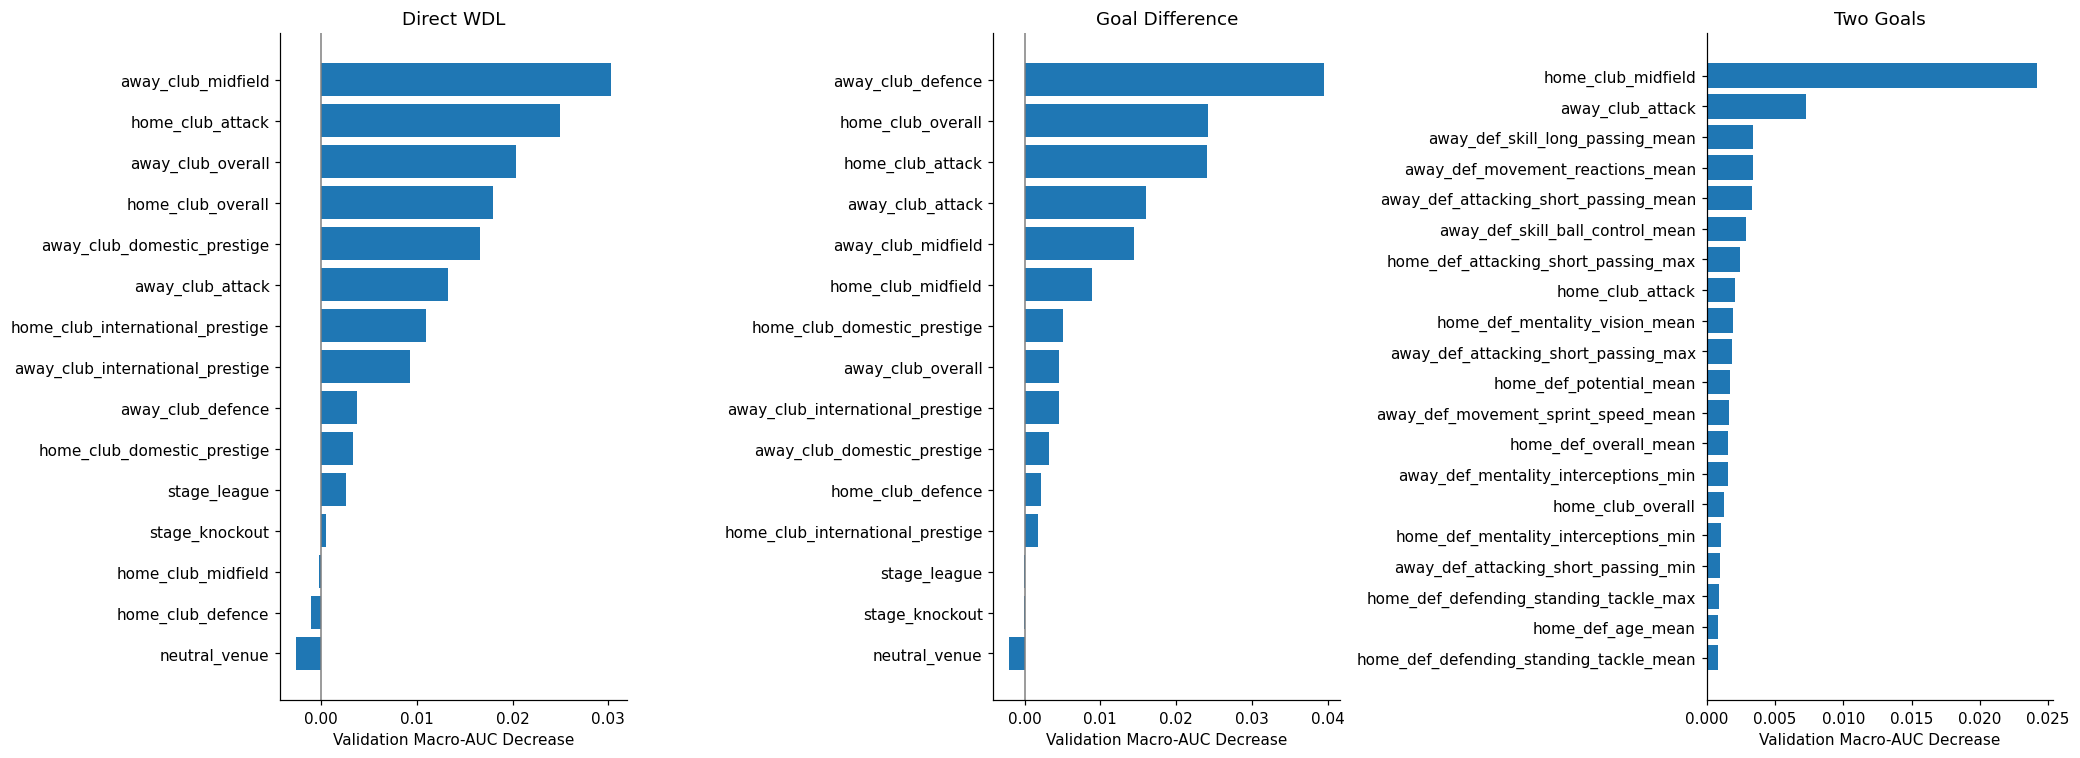

In [74]:
def get_feature_group(col):
    if '_club_' in col or col in ['neutral_venue', 'stage_league', 'stage_knockout']:
        return 'Club / Context'

    for pos in ['gk', 'def', 'mid', 'att']:
        if f'_{pos}_' in col:
            return pos.upper()

    return 'Other'


group_rows = []

for _, winner in best_by_route.iterrows():
    key = (
        winner['route'],
        winner['feature_set'],
        winner['model']
    )

    _, Xvalid, cols = prepare_group(winner['feature_set'])
    yvalid = y_wdl.loc[valid_idx].to_numpy()

    base_auc = evaluate_wdl(
        yvalid, predict_route(key, Xvalid)
    )['macro_auc']

    groups = {}
    for col in cols:
        g = get_feature_group(col)
        groups.setdefault(g, []).append(col)

    for group_name, group_cols in groups.items():
        drops = []

        for repeat in range(10):
            shuffled = Xvalid.copy()
            idx = rng.permutation(len(Xvalid))

            # Shuffle all columns in the group together
            shuffled.loc[:, group_cols] = (
                Xvalid[group_cols].iloc[idx].to_numpy()
            )

            auc_after = evaluate_wdl(
                yvalid, predict_route(key, shuffled)
            )['macro_auc']

            drops.append(base_auc - auc_after)

        group_rows.append({
            'route': key[0],
            'feature_set': key[1],
            'model': key[2],
            'group': group_name,
            'n_features': len(group_cols),
            'auc_drop': np.mean(drops),
            'std': np.std(drops)
        })

group_importance = pd.DataFrame(group_rows)
group_importance.to_csv(OUT / 'group_permutation_importance.csv', index=False)

display(group_importance.sort_values(['route', 'auc_drop'], ascending=[True, False]).round(4))

# Visualize the 20 most important individual features per route
fig, axes = plt.subplots(1, 3, figsize=(19, 7))

for ax, (route, subset) in zip(axes, importance_all.groupby('route')):
    top = subset.nlargest(20, 'auc_drop').sort_values('auc_drop')
    ax.barh(top['feature'], top['auc_drop'])
    ax.axvline(0, color='gray', linewidth=1)
    ax.set_title(route)
    ax.set_xlabel('Validation Macro-AUC Decrease')

plt.tight_layout()
plt.show()

In [ ]:

# XGBoost importance for ALL feature sets and routes

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

IMP_OUT = Path('model/results/position_nonlinear/xgb_importance')
IMP_OUT.mkdir(parents=True, exist_ok=True)

def feature_type(name):
    if '_club_' in name or name in [
        'neutral_venue', 'stage_league', 'stage_knockout'
    ]:
        return 'Club / Context'
    return 'Player'

def get_xgb_importance(pipeline, columns):
    model = pipeline.steps[-1][1]
    values = model.feature_importances_

    return pd.Series(values, index=columns, dtype=float)

importance_records = []

for group in GROUPS:
    for route in ['Direct WDL', 'Goal Difference', 'Two Goals']:

        key = (route, group, 'XGBoost')

        if key not in model_bank:
            print('Not found:', key)
            continue

        pack = model_bank[key]
        columns = pack['columns']
        models = pack['models']

        if route == 'Two Goals':
            imp_home = get_xgb_importance(models[0], columns)
            imp_away = get_xgb_importance(models[1], columns)
            imp = (imp_home + imp_away) / 2
        else:
            imp_home = pd.Series(np.nan, index=columns)
            imp_away = pd.Series(np.nan, index=columns)
            imp = get_xgb_importance(models[0], columns)

        for feature in columns:
            importance_records.append({
                'route': route,
                'feature_set': group,
                'feature': feature,
                'feature_type': feature_type(feature),
                'importance': imp[feature],
                'home_goals_importance': imp_home[feature],
                'away_goals_importance': imp_away[feature]
            })

xgb_importance = pd.DataFrame(importance_records)

xgb_importance.to_csv(
    IMP_OUT / 'xgb_all_feature_importance.csv',
    index=False
)

print('Total importance records:', len(xgb_importance))

# Show ALL player features, ranked within each experiment
for group in GROUPS:
    for route in ['Direct WDL', 'Goal Difference', 'Two Goals']:
        subset = xgb_importance[
            (xgb_importance['feature_set'] == group) &
            (xgb_importance['route'] == route) &
            (xgb_importance['feature_type'] == 'Player')
        ].sort_values('importance', ascending=False)

        if subset.empty:
            continue

        print(f'\n{group} | {route}')
        display(subset[['feature', 'importance','home_goals_importance','away_goals_importance']].round(5).reset_index(drop=True))
